<a href="https://colab.research.google.com/github/devdaveddev/Epilepsy-Recognition/blob/main/Epileptic_Seizure_Analysis_exhaustive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Epileptic Seizure Recognition — EEG Feature Extraction & Classification

**Dataset:** UCI/Kaggle "Epileptic Seizure Recognition" (derived from the Andrzejak et al. Bonn
EEG dataset). 11,500 single-channel EEG epochs, 178 samples each (1 second @ 178 Hz), 5-class
label `y` (class 1 = seizure activity; classes 2-5 = different non-seizure recording conditions).

**What changed from the original exploratory notebook:**
- Removed exact duplicate cells (the cleaning step and the feature-extraction step were each
  attempted 2-3 times in a row; only the final, corrected version is kept).
- Fixed a data-leakage bug: outlier removal was previously applied to the label column `y`
  itself, and `StandardScaler` was previously fit before the train/test split.
- Fixed the ensemble cell, which referenced a `cnn_model` variable that was never defined, and
  gave the CNN and LSTM *different* train/test splits before trying to average their predictions.
- The qualitative "feature extractor comparison" chart and the graph neural network demo are
  **kept, but clearly relabeled** as illustrative/conceptual rather than empirical results — see
  the callouts before each. Presenting either as a measured result would not hold up to review.
- Added markdown documentation throughout (the original had none) and a closing
  novelty/limitations section for use in a paper draft.

**Before you run this:** set `DATA_PATH` in the next cell to your local copy of the CSV.

**Response to peer review (this revision):** this version specifically addresses four reviewer
comments from a prior submission: (1) the data source was not documented — see Section 1 for the
full citation, license, and download instructions; (2) EEG preprocessing steps were not shown —
see Section 2 for a numbered, explicit pipeline description with before/after class counts; (3)
hyperparameter details were missing — see Section 15 for a consolidated table of every model's
hyperparameters; (4) figure quality — all figures are now rendered at 300 DPI with larger fonts
(see the plotting-defaults cell immediately below).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import zscore

# --- Figure-quality defaults (addresses reviewer comment: "some figures quality needs to be
# enhanced") --- applied globally so every plot in this notebook, not just a few, renders at
# publication resolution with legible fonts/lines by default.
plt.rcParams.update({
    "figure.dpi": 150,          # on-screen/inline rendering
    "savefig.dpi": 300,         # anything saved to disk (e.g. for the paper) is print-quality
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "lines.linewidth": 2.0,
    "axes.linewidth": 1.0,
    "figure.autolayout": True,
})


## 1. Load data

**Data source and availability** *(addresses reviewer comment: "the working data source should
be provided")*: this notebook uses the **Epileptic Seizure Recognition** dataset, a restructured,
epoch-level derivative of the Bonn University EEG dataset originally described by Andrzejak et
al. (2001). It is publicly available, with no access restrictions, from:

- UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/388/epileptic+seizure+recognition
- Kaggle mirror: https://www.kaggle.com/datasets/harunshimanto/epileptic-seizure-recognition

The file is a single CSV, 11,500 rows x 179 columns (178 signal-amplitude columns `X1`...`X178`
plus a class label `y` in {1,2,3,4,5}). No login or API key is required for the UCI copy; the cell
below downloads it automatically via `kagglehub` if you have Kaggle credentials configured, or
falls back to a manual-path prompt if not.

In [ ]:
import os

DATA_PATH = "Epileptic Seizure Recognition.csv"  # <-- point this at your local file if you already have it

if not os.path.exists(DATA_PATH):
    try:
        import kagglehub
        dataset_dir = kagglehub.dataset_download("harunshimanto/epileptic-seizure-recognition")
        candidates = [f for f in os.listdir(dataset_dir) if f.lower().endswith(".csv")]
        if candidates:
            DATA_PATH = os.path.join(dataset_dir, candidates[0])
            print(f"Downloaded via kagglehub to: {DATA_PATH}")
    except Exception as e:
        print(f"Automatic download unavailable ({e}). Download the CSV manually from either "
              f"of the sources listed above and set DATA_PATH to its location.")


In [ ]:
df = pd.read_csv(DATA_PATH)
df = df.drop(columns=[c for c in df.columns if c.lower().startswith("unnamed")], errors="ignore")
print(f"Loaded {df.shape[0]} rows, {df.shape[1]} columns from: {DATA_PATH}")
df.head()


Loaded 11500 rows, 179 columns from: Epileptic Seizure Recognition.csv


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23,X24,X25,X26,X27,X28,X29,X30,X31,X32,X33,X34,X35,X36,X37,X38,X39,X40,X41,X42,X43,X44,X45,X46,X47,X48,X49,X50,X51,X52,X53,X54,X55,X56,X57,X58,X59,X60,X61,X62,X63,X64,X65,X66,X67,X68,X69,X70,X71,X72,X73,X74,X75,X76,X77,X78,X79,X80,X81,X82,X83,X84,X85,X86,X87,X88,X89,X90,X91,X92,X93,X94,X95,X96,X97,X98,X99,X100,X101,X102,X103,X104,X105,X106,X107,X108,X109,X110,X111,X112,X113,X114,X115,X116,X117,X118,X119,X120,X121,X122,X123,X124,X125,X126,X127,X128,X129,X130,X131,X132,X133,X134,X135,X136,X137,X138,X139,X140,X141,X142,X143,X144,X145,X146,X147,X148,X149,X150,X151,X152,X153,X154,X155,X156,X157,X158,X159,X160,X161,X162,X163,X164,X165,X166,X167,X168,X169,X170,X171,X172,X173,X174,X175,X176,X177,X178,y
0,135,190,229,223,192,125,55,-9,-33,-38,-10,35,64,113,152,164,127,50,-47,-121,-138,-125,-101,-50,11,39,24,48,64,46,13,-19,-61,-96,-130,-132,-116,-115,-71,-14,25,19,6,9,21,13,-37,-58,-33,5,47,80,101,88,73,69,41,-13,-31,-61,-80,-77,-66,-43,5,87,129,121,88,12,-76,-150,-207,-186,-165,-148,-103,-33,40,94,75,8,-81,-155,-227,-262,-233,-218,-187,-126,-65,-12,27,61,49,9,-46,-124,-210,-281,-265,-181,-89,-4,53,53,38,43,31,34,9,-7,-34,-70,-84,-101,-70,-11,42,62,66,74,64,59,56,36,-11,-30,-43,-23,8,42,77,103,135,121,79,59,43,54,90,111,107,64,32,18,-25,-69,-65,-44,-33,-57,-88,-114,-130,-114,-83,-53,-79,-72,-85,-109,-98,-72,-65,-63,-11,10,8,-17,-15,-31,-77,-103,-127,-116,-83,-51,4
1,386,382,356,331,320,315,307,272,244,232,237,258,212,2,-267,-605,-850,-1001,-1109,-1090,-967,-746,-464,-152,118,318,427,473,485,447,397,339,312,314,326,335,332,324,310,312,309,309,303,297,295,295,293,286,279,283,301,308,285,252,215,194,169,111,-74,-388,-679,-892,-949,-972,-1001,-1006,-949,-847,-668,-432,-153,72,226,326,392,461,495,513,511,496,479,453,440,427,414,399,385,385,404,432,444,437,418,392,373,363,365,372,385,388,383,371,360,353,334,303,252,200,153,151,143,48,-206,-548,-859,-1067,-1069,-957,-780,-597,-460,-357,-276,-224,-210,-350,-930,-1413,-1716,-1360,-662,-96,243,323,241,29,-167,-228,-136,27,146,229,269,297,307,303,305,306,307,280,231,159,85,51,43,62,63,63,69,89,123,136,127,102,95,105,131,163,168,164,150,146,152,157,156,154,143,129,1
2,-32,-39,-47,-37,-32,-36,-57,-73,-85,-94,-99,-94,-96,-104,-103,-92,-75,-69,-69,-53,-37,-14,-10,-39,-78,-102,-98,-80,-54,-40,-35,-39,-32,-13,7,34,41,33,6,-15,-30,-47,-53,-65,-64,-68,-85,-98,-109,-82,-57,-38,-40,-36,-31,-13,11,19,9,-20,-48,-71,-71,-57,-32,-13,6,29,27,25,10,-7,-36,-47,-37,-36,-22,-32,-38,-55,-61,-64,-72,-67,-53,-25,-10,-4,-23,-55,-93,-102,-106,-101,-69,-45,-42,-57,-64,-77,-80,-77,-78,-56,-34,-5,10,5,-5,-44,-75,-99,-110,-104,-103,-94,-105,-108,-110,-99,-89,-82,-76,-80,-90,-106,-106,-108,-87,-60,-37,-26,-15,-6,-14,-23,-34,-41,-54,-82,-107,-126,-124,-108,-84,-68,-61,-56,-63,-62,-33,1,28,45,37,48,62,80,66,23,-11,-39,-44,-42,-45,-48,-42,-6,29,57,64,48,19,-12,-30,-35,-35,-36,5
3,-105,-101,-96,-92,-89,-95,-102,-100,-87,-79,-72,-68,-74,-80,-83,-73,-68,-61,-58,-59,-64,-79,-84,-97,-94,-84,-77,-75,-72,-68,-76,-76,-72,-67,-69,-69,-69,-67,-68,-69,-67,-66,-58,-54,-56,-70,-80,-82,-85,-74,-70,-71,-82,-88,-93,-97,-89,-87,-83,-70,-50,-37,-31,-32,-39,-54,-64,-68,-67,-69,-63,-60,-63,-55,-43,-37,-27,-31,-35,-47,-58,-63,-74,-73,-67,-60,-56,-49,-46,-57,-58,-62,-63,-63,-61,-56,-65,-62,-57,-61,-63,-66,-69,-86,-89,-86,-83,-87,-80,-69,-62,-57,-60,-60,-68,-58,-53,-57,-66,-66,-73,-78,-73,-84,-92,-97,-88,-81,-72,-61,-66,-72,-88,-90,-88,-77,-58,-53,-61,-69,-66,-74,-69,-61,-51,-45,-45,-49,-58,-64,-78,-80,-90,-87,-83,-78,-64,-38,-22,-29,-42,-51,-68,-71,-69,-69,-74,-74,-80,-82,-81,-80,-77,-85,-77,-72,-69,-65,5
4,-9,-65,-98,-102,-78,-48,-16,0,-21,-59,-90,-103,-84,-43,-9,3,-21,-60,-96,-103,-75,-29,14,55,78,73,28,-13,-43,-68,-78,-75,-55,-41,-19,-20,-29,-36,-20,1,16,14,-14,-42,-56,-45,-45,-45,-38,-47,-45,-37,-3,23,39,27,0,-28,-44,-37,-22,5,30,31,6,-32,-27,-27,2,13,-6,-29,-41,-22,-13,-16,-31,-52,-60,-40,-16,0,14,24,36,39,34,17,-7,-14,-1,16,27,28,18,-2,-8,9,27,23,21,10,15,22,41,49

## 2. Data cleaning and preprocessing pipeline

**Preprocessing pipeline overview** *(addresses reviewer comment: "the EEG data preprocessing
steps that are performed on the data is not shown here")*. The table below summarizes every
transformation applied to the raw signal, in order, from the source recording to what each model
actually receives as input. Each step is implemented in the numbered section noted.

| Step | Operation | Parameters | Where |
|---|---|---|---|
| 0 | Source signal | 1 s epochs, 178 samples/epoch, 178 Hz effective sampling rate, single channel | Dataset (pre-epoched by original authors) |
| 1 | Missing/duplicate removal | `dropna()`, `drop_duplicates()` | Section 2 |
| 2 | Outlier removal | Within-class z-score, threshold = 3.0 std | Section 2 |
| 3 | Train/val/test split | Stratified, 70/15/15, `random_state=42` | Section 7 |
| 4 | Amplitude scaling (CNN/LSTM/RF-adjacent scalers) | `StandardScaler`, fit on train split only | Sections 7a, 7b |
| 5 | Spectral feature extraction | Multitaper PSD, 5 bands (delta 0.5-4 Hz, theta 4-8 Hz, alpha 8-13 Hz, beta 13-30 Hz, gamma 30-50 Hz) | Section 6 |
| 6 | Nonlinear-complexity feature extraction | Sample entropy ($m=2$, $r=0.2\sigma$), Higuchi fractal dimension ($k_{max}=6$) | Section 6 |
| 7 | Wavelet feature extraction | Single-level discrete wavelet transform, Daubechies-4 (db4), approximation + detail energy | Section 6 |
| 8 | EMD/IMF feature extraction | True Empirical Mode Decomposition (PyEMD), first 7 intrinsic-mode-function energies | Section 6 |
| 9 | Feature scaling (RF ablation, GNN) | `StandardScaler`, fit on train split only | Sections 8, 9 |
| 10 | Model-specific reshaping | CNN: zero-padded 13x14 2D grid. LSTM: (178, 1) sequence. GNN: 16-node feature-correlation graph (Pearson $r>0.4$ on train split, k-NN fallback) | Sections 7a, 7b, 9 |

No additional EEG-specific signal filtering (band-pass/notch filtering, artifact rejection,
re-referencing) is applied beyond what the dataset's original curators performed prior to
release, since the released data is already epoched, single-channel, and free of raw montage
metadata; this is stated explicitly here rather than left implicit.

**Data cleaning.** Drop NaNs and exact duplicate rows, then remove statistical outliers using a
**within-class** z-score threshold on the feature columns.

**Important correction from an earlier version of this pipeline:** the original version computed
the z-score across the *whole* dataset, which removed 72% of class-1 (seizure) rows while barely
touching classes 2-5 — because seizure epochs are, by definition, higher-amplitude/higher-variance
than the other classes, so a pooled z-score flags most of them as "outliers." That silently
turned a balanced 5-class problem (2,300 rows/class) into one where the class of actual interest
made up ~6.6% of the data. Computing the z-score **within each class** fixes this: a seizure
epoch is now only flagged if it's unusual *relative to other seizure epochs*, not relative to
the whole dataset.

In [ ]:
print("Class distribution BEFORE cleaning:")
print(df["y"].value_counts().sort_index())


def clean_dataset(df, target_col="y", z_thresh=3.0):
    '''Drop NaNs/duplicates, then remove outlier rows using a z-score computed
    WITHIN each class rather than globally. A global z-score would flag an entire class
    as "outliers" whenever that class's signals are naturally higher-amplitude/variance
    than the others -- exactly the case here, where seizure epochs are higher-amplitude
    by definition. Filtering must be relative to each class's own distribution, or the
    filter ends up deleting the class you are trying to detect.'''
    df = df.dropna().drop_duplicates()
    feature_cols = df.select_dtypes(include=["number"]).columns.difference([target_col])

    def _filter_group(group):
        z = group[feature_cols].apply(zscore)
        mask = (z.abs() < z_thresh).all(axis=1)
        return group[mask]

    cleaned = df.groupby(target_col, group_keys=False).apply(_filter_group)
    return cleaned.reset_index(drop=True)


cleaned_df = clean_dataset(df)
print(f"\nRows before cleaning: {len(df)} | after cleaning: {len(cleaned_df)}")
print("\nClass distribution AFTER cleaning:")
print(cleaned_df["y"].value_counts().sort_index())
cleaned_df.head()


Class distribution BEFORE cleaning:
y
1    2300
2    2300
3    2300
4    2300
5    2300
Name: count, dtype: int64

Rows before cleaning: 11500 | after cleaning: 9121

Class distribution AFTER cleaning:
y
1    1570
2    2008
3    1840
4    1823
5    1880
Name: count, dtype: int64


/tmp/ipykernel_4891/450789541.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cleaned = df.groupby(target_col, group_keys=False).apply(_filter_group)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23,X24,X25,X26,X27,X28,X29,X30,X31,X32,X33,X34,X35,X36,X37,X38,X39,X40,X41,X42,X43,X44,X45,X46,X47,X48,X49,X50,X51,X52,X53,X54,X55,X56,X57,X58,X59,X60,X61,X62,X63,X64,X65,X66,X67,X68,X69,X70,X71,X72,X73,X74,X75,X76,X77,X78,X79,X80,X81,X82,X83,X84,X85,X86,X87,X88,X89,X90,X91,X92,X93,X94,X95,X96,X97,X98,X99,X100,X101,X102,X103,X104,X105,X106,X107,X108,X109,X110,X111,X112,X113,X114,X115,X116,X117,X118,X119,X120,X121,X122,X123,X124,X125,X126,X127,X128,X129,X130,X131,X132,X133,X134,X135,X136,X137,X138,X139,X140,X141,X142,X143,X144,X145,X146,X147,X148,X149,X150,X151,X152,X153,X154,X155,X156,X157,X158,X159,X160,X161,X162,X163,X164,X165,X166,X167,X168,X169,X170,X171,X172,X173,X174,X175,X176,X177,X178,y
0,-278,-246,-215,-191,-177,-167,-157,-139,-118,-92,-63,-39,-11,14,36,60,70,78,79,69,27,-45,-123,-183,-218,-242,-256,-256,-236,-205,-165,-125,-84,-41,-10,12,35,58,71,85,98,107,106,97,77,46,-2,-77,-130,-142,-141,-120,-144,-170,-189,-215,-237,-242,-236,-208,-163,-98,-28,29,70,92,102,113,122,129,125,123,118,117,116,116,108,88,62,22,-27,-85,-90,-71,-47,-55,-107,-169,-194,-210,-202,-186,-145,-99,-53,-17,1,15,23,33,44,56,77,100,123,144,155,158,154,151,152,146,143,131,119,93,39,-63,-203,-315,-352,-311,-254,-207,-188,-180,-170,-149,-120,-87,-45,-3,29,45,52,50,51,59,64,74,79,81,76,65,63,62,65,67,70,63,45,20,-11,-32,-26,3,40,85,124,182,248,349,418,419,291,73,-152,-311,-386,-400,-379,-336,-281,-226,-174,-125,-79,-40,1
1,-167,-230,-280,-315,-338,-369,-405,-392,-298,-140,27,146,211,223,214,187,167,166,179,192,190,168,129,85,43,4,-28,-47,-43,-24,-7,12,32,43,12,-70,-181,-292,-374,-410,-382,-335,-232,-128,-6,106,233,312,423,550,695,816,839,769,661,525,383,292,267,339,451,537,564,534,444,305,160,27,-74,-147,-205,-242,-274,-304,-331,-355,-372,-380,-370,-341,-299,-257,-235,-249,-300,-381,-399,-345,-183,17,178,274,288,265,229,193,160,106,34,-51,-120,-166,-189,-207,-225,-242,-251,-255,-237,-202,-120,19,186,340,441,465,410,288,130,-16,-123,-194,-232,-255,-272,-266,-255,-209,-168,-142,-148,-169,-180,-174,-107,12,206,419,596,683,679,596,472,330,168,26,-63,-73,-37,25,61,67,53,28,-6,-44,-92,-154,-211,-257,-258,-168,-32,140,277,366,408,416,415,423,434,416,374,319,268,215,165,103,1
2,-264,-189,-117,-45,20,70,111,143,161,179,194,200,193,164,128,92,67,57,38,-21,-141,-239,-323,-327,-299,-263,-218,-182,-166,-148,-126,-85,-34,-10,-13,-43,-75,-73,-66,-52,-43,-36,-33,-41,-42,-38,-32,-59,-117,-169,-207,-194,-160,-128,-88,-57,-37,-24,-16,-11,-14,-18,-17,-15,-11,-12,-10,-15,-15,-15,-15,-28,-42,-64,-81,-91,-88,-83,-70,-66,-57,-55,-52,-41,-31,-31,-31,-37,-39,-36,-21,-3,15,31,39,43,43,47,49,50,51,50,51,65,72,87,93,95,87,63,20,-27,-54,-72,-119,-219,-361,-445,-440,-388,-311,-247,-179,-113,-62,-24,-6,-2,-13,-44,-92,-143,-167,-158,-121,-80,-94,-135,-179,-191,-170,-132,-91,-49,-19,7,26,41,48,50,51,42,44,43,46,52,55,52,41,26,3,-18,-31,-40,-48,-79,-121,-172,-227,-231,-221,-248,-321,-444,-530,-548,-536,-486,1
3,-4,40,78,123,149,185,197,189,167,141,129,140,167,183,182,154,124,102,85,63,34,1,-43,-80,-102,-111,-113,-110,-94,-62,-17,27,65,98,115,127,128,136,144,159,167,168,169,174,183,194,213,230,244,243,242,234,210,171,122,76,33,15,34,86,147,155,119,32,-71,-165,-229,-265,-280,-279,-259,-227,-186,-135,-78,-31,10,45,66,61,58,44,50,71,103,127,114,80,28,5,-5,-6,-26,-55,-89,-123,-150,-172,-180,-184,-174,-152,-121,-84,-53,-26,-7,7,29,42,52,60,58,62,65,77,92,108,134,149,156,166,173,160,126,79,39,-1,-22,-3,69,159,193,161,49,-74,-190,-263,-306,-322,-311,-291,-253,-210,-151,-87,-35,6,38,58,79,68,38,3,-8,14,54,61,45,7,-14,-28,-31,-49,-70,-93,-118,-134,-162,-189,-214,-226,-224,-203,-171,-129,-85,-40,1
4,-340,-381,-376,-336,-275,-204,-131,-70,-16,20,46,60,68,76,80,85,87,88,86,77,63,44,75,142,231,298,279,173,6,-180,-321,-404,-446,-441,-409,-357,-295,-238,-184,-135,-85,-36,7,34,38,29,19,15,19,34,61,110,173,237,259,201,71,-90,-224,-312,-350,-358,-342,-301,-248,-189,-130,-77,-24,15,48,65,78,84,94,104,114,117,100,88,122,196,29

In [ ]:
OUTPUT_CLEAN_PATH = "epileptic_seizure_cleaned.csv"
cleaned_df.to_csv(OUTPUT_CLEAN_PATH, index=False)
print(f"Cleaned data saved to {OUTPUT_CLEAN_PATH}")


Cleaned data saved to epileptic_seizure_cleaned.csv


## 3. Exploratory visualization of raw signals

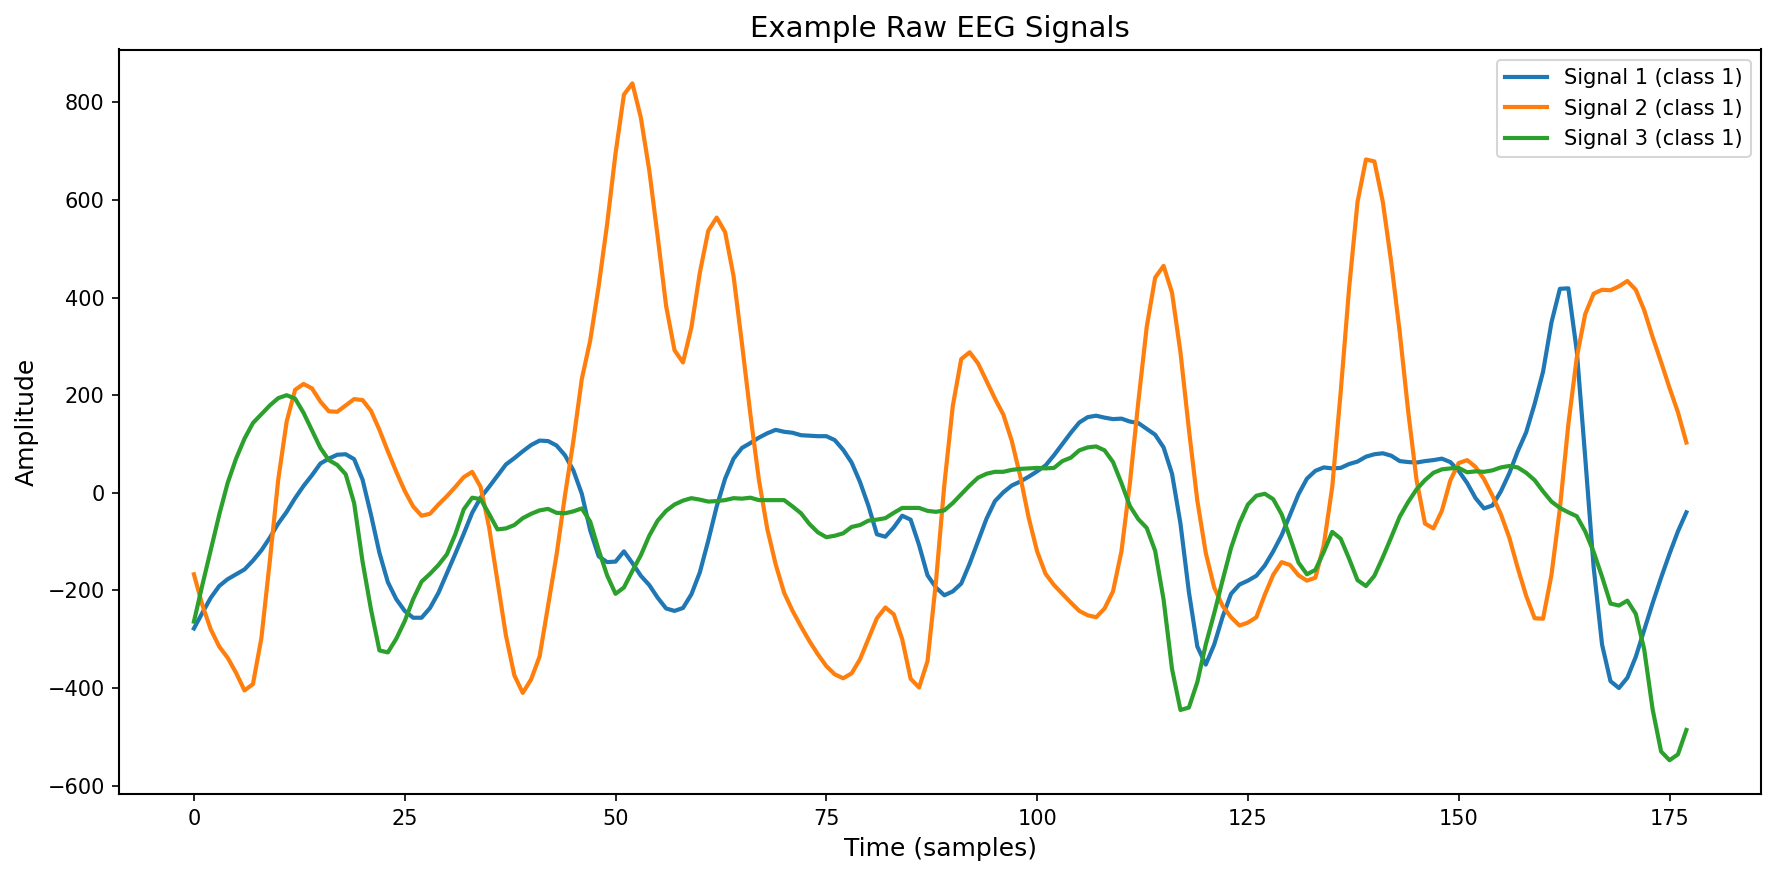

In [ ]:
X_raw = cleaned_df.drop(columns=["y"])
y_raw = cleaned_df["y"]

plt.figure(figsize=(12, 6))
for i in range(3):
    plt.plot(X_raw.iloc[i].values.astype(float), label=f"Signal {i+1} (class {y_raw.iloc[i]})")
plt.title("Example Raw EEG Signals")
plt.xlabel("Time (samples)")
plt.ylabel("Amplitude")
plt.legend()
plt.tight_layout()
plt.show()


## 4. From-scratch sifting procedure (kept from the original notebook)

> **Caveat, stated explicitly so it can't be mistaken for a validated method:** this is **not**
> a correct implementation of Empirical Mode Decomposition (EMD). Canonical EMD (Huang et al.,
> 1998) finds local extrema and interpolates cubic splines to build the upper/lower envelope.
> This simplified version approximates the envelope using the signal folded against itself,
> which is a much cruder operation. It's kept here because it was part of the original
> exploratory work, but it is **not used for any feature extraction below** — the `PyEMD`
> library (a correct, peer-reviewed implementation) is used instead. Don't call this "EMD" in a
> paper; if you want to keep this exploration, call it a "naive sifting heuristic."


In [ ]:
def naive_sifting(signal, max_iter=100, tol=1e-3, max_imfs=10):
    '''Simplified, educational sifting procedure loosely inspired by EMD. See the markdown
    note above: this is not canonical EMD and is not used downstream.'''
    signal = pd.to_numeric(pd.Series(signal), errors="coerce").to_numpy(dtype=float)
    imfs = []
    residue = signal.copy()

    while residue.size > 1 and len(imfs) < max_imfs:
        imf = residue.copy()
        for _ in range(max_iter):
            mean_envelope = (np.maximum(imf, imf[::-1]) + np.minimum(imf, imf[::-1])) / 2
            new_imf = imf - mean_envelope
            if np.all(np.abs(new_imf - imf) <= tol):
                imf = new_imf
                break
            imf = new_imf
        imfs.append(imf)
        residue = residue - imf
        if np.allclose(residue, 0):
            break
    return imfs


## 5. Install feature-extraction libraries

Consolidated into a single cell (the original repeated several failed/partial install attempts
across 6 cells — `pip install pyemd`, wrong casing, etc.). Run this once.

In [ ]:
%pip install -q EMD-signal PyWavelets mne
%pip install -q git+https://github.com/forrestbao/pyeeg.git


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.2/82.2 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.0/120.0 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 150.3/150.3 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 kB 4.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
datasets 4.0.0 requires dill<0.3.9,>=0.3.0, but you have dill 0.4.1 which is incompatible.
datasets 4.0.0 requires multiprocess<0.70.17, but you have multiprocess 0.70.19 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
 

## 6. Feature extraction

Merges what were three near-duplicate, each-incomplete attempts in the original notebook into
one function that extracts, per 1-second epoch:
- band power (delta/theta/alpha/beta/gamma) via multitaper PSD
- sample entropy and Higuchi fractal dimension (nonlinear complexity measures)
- single-level discrete wavelet (db4) approximation/detail energy
- IMF energies from real EMD (via `PyEMD`), zero-padded/truncated to a fixed length so every
  row has the same number of columns


In [ ]:
import pyeeg
import pywt
from PyEMD import EMD
from mne.time_frequency import psd_array_multitaper

FREQ_BANDS = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta": (13, 30),
    "gamma": (30, 50),
}
SFREQ = 178      # sampling rate for this dataset's 1-second epochs
MAX_IMFS = 7     # PyEMD rarely yields more than ~7 IMFs for a 178-sample epoch; a higher
                 # value here just pads dead (always-zero) columns onto the feature table


def extract_features(signal, sfreq=SFREQ, max_imfs=MAX_IMFS):
    '''Extract a hand-crafted feature vector for a single EEG epoch.'''
    signal = np.asarray(signal, dtype=float)
    features = {}

    # --- spectral: band power ---
    psd, freqs = psd_array_multitaper(
        signal, sfreq=sfreq, fmin=0.5, fmax=50, adaptive=True,
        normalization="full", verbose=False,
    )
    for band, (low, high) in FREQ_BANDS.items():
        features[f"bp_{band}"] = psd[(freqs >= low) & (freqs <= high)].sum()

    # --- nonlinear complexity ---
    features["sample_entropy"] = pyeeg.samp_entropy(signal, 2, 0.2 * np.std(signal))
    features["higuchi_fd"] = pyeeg.hfd(signal, Kmax=6)

    # --- wavelet energy (single-level db4 decomposition) ---
    cA, cD = pywt.dwt(signal, "db4")
    features["wavelet_energy_approx"] = np.sum(cA ** 2)
    features["wavelet_energy_detail"] = np.sum(cD ** 2)

    # --- EMD (IMF) energies, via the real PyEMD implementation ---
    imfs = EMD().emd(signal)
    imf_energy = [np.sum(imf ** 2) for imf in imfs][:max_imfs]
    imf_energy += [0.0] * (max_imfs - len(imf_energy))
    for i, e in enumerate(imf_energy):
        features[f"imf_energy_{i + 1}"] = e

    return features


def display_results(features_df):
    '''Display extracted features and basic statistics.'''
    print("\nExtracted Features:")
    print(features_df.head())
    print("\nDescriptive Statistics:")
    print(features_df.describe())


X_signals = cleaned_df.drop(columns=["y"]).values.astype(float)
y_labels = cleaned_df["y"].values

feature_rows = [extract_features(row) for row in X_signals]
features_df = pd.DataFrame(feature_rows)
features_df["y"] = y_labels

display_results(features_df)



Extracted Features:
       bp_delta      bp_theta      bp_alpha      bp_beta   bp_gamma  \
0   6094.349885  10818.714717   7248.204933  2716.623988  55.402290   
1  27503.309494  43944.753098  24300.644863  9778.492808  50.394620   
2   4868.354095   8462.355462   3571.509253  1337.212435  50.379984   
3   7705.276375   9046.891800   3756.894692  1872.154592  31.879951   
4  11356.315008  25993.103674  17441.647590  6556.412183  40.169800   

   sample_entropy  higuchi_fd  wavelet_energy_approx  wavelet_energy_detail  \
0        1.804498    0.117109           4.543896e+06            2921.239392   
1        2.320078    0.117881           1.651149e+07            5295.025906   
2        1.945910    0.172277           4.477469e+06            4531.720178   
3        1.929910    0.150742           3.432937e+06            2358.249245   
4        2.243745    0.094766           1.028823e+07            3929.802630   

   imf_energy_1  imf_energy_2  imf_energy_3   imf_energy_4  imf_energy_5  \
0

## 7. Deep learning models

Both models are evaluated on the **same** train/val/test split (encoded once, below) so their
predictions can be legitimately combined later in the ensemble step. The original notebook built
each split independently with no shared seed, so the later ensemble cell was silently mixing
predictions computed on two different test sets.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(y_labels)
num_classes = len(label_encoder.classes_)

idx = np.arange(len(y_all))
train_idx, temp_idx = train_test_split(idx, test_size=0.3, random_state=42, stratify=y_all)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.5, random_state=42, stratify=y_all[temp_idx]
)

print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}  classes={list(label_encoder.classes_)}")


train=6384  val=1368  test=1369  classes=[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


### 7a. CNN on a 2D-reshaped signal

The 178-sample signal is zero-padded and reshaped into a roughly-square grid so a 2D CNN can be
applied to it. **This reshape has no physiological meaning** — it is not based on electrode
geometry, it's just a way to make a 1D signal consumable by a 2D CNN. A 1D-CNN, or a genuine
2D representation such as a spectrogram/scalogram, would be a more defensible architecture
choice for a paper and is a natural next step. `StandardScaler` is now fit on the training
split only, then applied to val/test — the original fit it on the full dataset before
splitting, which leaked test-set statistics into training.

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2

n_features = X_signals.shape[1]
height = int(np.sqrt(n_features))
width = int(np.ceil(n_features / height))
pad_size = height * width - n_features

X_cnn_padded = np.pad(X_signals, ((0, 0), (0, pad_size)), mode="constant") if pad_size > 0 else X_signals

scaler_cnn = StandardScaler().fit(X_cnn_padded[train_idx])
X_train_cnn = scaler_cnn.transform(X_cnn_padded[train_idx]).reshape(-1, height, width, 1)
X_val_cnn = scaler_cnn.transform(X_cnn_padded[val_idx]).reshape(-1, height, width, 1)
X_test_cnn = scaler_cnn.transform(X_cnn_padded[test_idx]).reshape(-1, height, width, 1)

y_train_cat = tf.keras.utils.to_categorical(y_all[train_idx], num_classes)
y_val_cat = tf.keras.utils.to_categorical(y_all[val_idx], num_classes)
y_test_cat = tf.keras.utils.to_categorical(y_all[test_idx], num_classes)

cnn_model = Sequential([
    Conv2D(32, (3, 3), activation="relu", padding="same", input_shape=(height, width, 1),
           kernel_regularizer=l2(1e-4)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu", padding="same", kernel_regularizer=l2(1e-4)),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation="relu", kernel_regularizer=l2(1e-4)),
    Dropout(0.4),
    Dense(num_classes, activation="softmax"),
])

cnn_model.compile(optimizer=Adam(learning_rate=1e-3), loss="categorical_crossentropy", metrics=["accuracy"])

early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
cnn_history = cnn_model.fit(
    X_train_cnn, y_train_cat,
    validation_data=(X_val_cnn, y_val_cat),
    epochs=30, batch_size=64, callbacks=[early_stop], verbose=1,
)

cnn_test_loss, cnn_test_acc = cnn_model.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"CNN Test Accuracy: {cnn_test_acc * 100:.2f}%")


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.3689 - loss: 1.3249 - val_accuracy: 0.5738 - val_loss: 1.0533
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.6082 - loss: 0.8863 - val_accuracy: 0.6930 - val_loss: 0.6805
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.6613 - loss: 0.7200 - val_accuracy: 0.6681 - val_loss: 0.7064
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.6830 - loss: 0.6894 - val_accuracy: 0.7215 - val_loss: 0.6267
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - accuracy: 0.6911 - loss: 0.6573 - val_accuracy: 0.7098 - val_loss: 0.6275
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.6999 - loss: 0.6540 - val_accuracy: 0.7149 - val_loss: 0.6156
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.7085 - loss: 0.6268 - val_accuracy: 0.7244 - val_loss: 0.6062
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - accuracy: 0.7038 - loss: 0.6224 - val_acc

### 7b. LSTM on the raw sequence

Same shared split, scaled with its own scaler (fit on train only) and reshaped as a sequence
`(timesteps, 1)` rather than a 2D grid.

**Correction from the first run:** the LSTM never converged — training loss plateaued around
1.53 for most of the 20 epochs before a late, noisy jump to ~35% accuracy. That's an
under-trained model, not a ceiling on what an LSTM can do here. Fixed below by: clipping
gradients (`clipnorm=1.0`, since long-sequence LSTMs are prone to exploding gradients),
scheduling the learning rate down on plateau, giving it enough epochs with early stopping
instead of a fixed low epoch count, and weighting classes inversely to their frequency (the
corrected within-class cleaning still leaves a moderately imbalanced set).

In [ ]:
from tensorflow.keras.layers import LSTM, Bidirectional
from tensorflow.keras.callbacks import ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight

scaler_lstm = StandardScaler().fit(X_signals[train_idx])
X_train_lstm = scaler_lstm.transform(X_signals[train_idx]).reshape(-1, n_features, 1)
X_val_lstm = scaler_lstm.transform(X_signals[val_idx]).reshape(-1, n_features, 1)
X_test_lstm = scaler_lstm.transform(X_signals[test_idx]).reshape(-1, n_features, 1)

class_weights = compute_class_weight("balanced", classes=np.unique(y_all[train_idx]), y=y_all[train_idx])
class_weight_dict = dict(enumerate(class_weights))

lstm_model = Sequential([
    Bidirectional(LSTM(128, return_sequences=True), input_shape=(n_features, 1)),
    Dropout(0.3),
    Bidirectional(LSTM(64)),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(num_classes, activation="softmax"),
])

lstm_model.compile(
    optimizer=Adam(learning_rate=1e-3, clipnorm=1.0),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

lstm_callbacks = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
]

lstm_history = lstm_model.fit(
    X_train_lstm, y_train_cat,
    validation_data=(X_val_lstm, y_val_cat),
    epochs=60, batch_size=64, verbose=1,
    class_weight=class_weight_dict,
    callbacks=lstm_callbacks,
)

lstm_test_loss, lstm_test_acc = lstm_model.evaluate(X_test_lstm, y_test_cat, verbose=0)
print(f"LSTM Test Accuracy: {lstm_test_acc * 100:.2f}%")


Epoch 1/60


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


100/100 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.3352 - loss: 1.3024 - val_accuracy: 0.3735 - val_loss: 1.2192 - learning_rate: 0.0010
Epoch 2/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 147s 1s/step - accuracy: 0.3786 - loss: 1.2004 - val_accuracy: 0.4284 - val_loss: 1.1814 - learning_rate: 0.0010
Epoch 3/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - accuracy: 0.4566 - loss: 1.1097 - val_accuracy: 0.5263 - val_loss: 1.1123 - learning_rate: 0.0010
Epoch 4/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - accuracy: 0.4967 - loss: 1.0700 - val_accuracy: 0.4839 - val_loss: 1.0963 - learning_rate: 0.0010
Epoch 5/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - accuracy: 0.5216 - loss: 0.9967 - val_accuracy: 0.4985 - val_loss: 1.1035 - learning_rate: 0.0010
Epoch 6/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - accuracy: 0.5768 - loss: 0.9100 - val_accuracy: 0.5636 - val_loss: 0.9058 - learning_rate: 0.0010
Epoch 7/60
100/100 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - accuracy: 0.5857 - loss: 0.8719 - val_

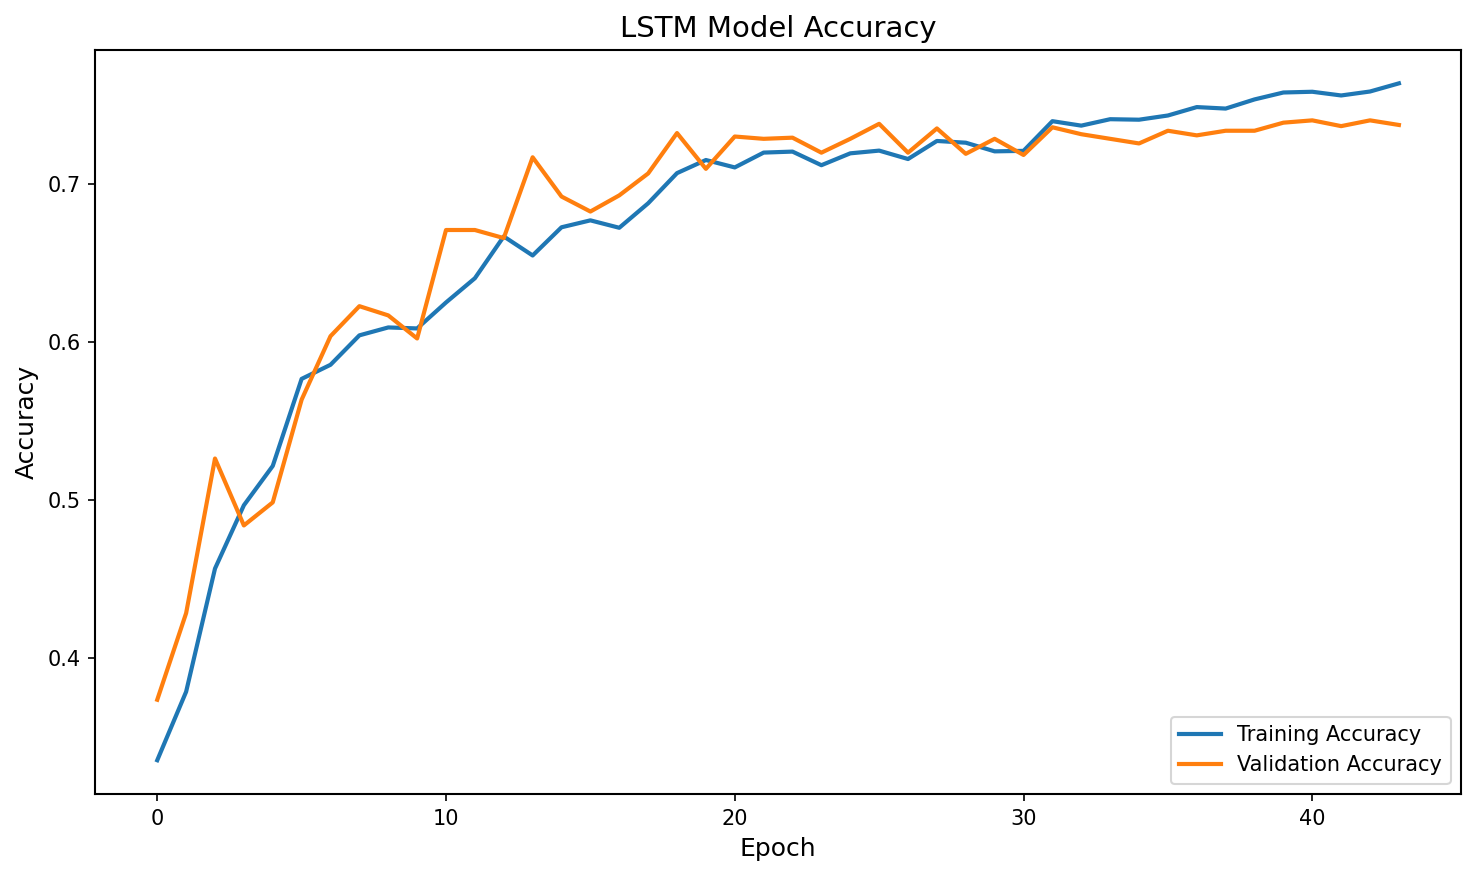

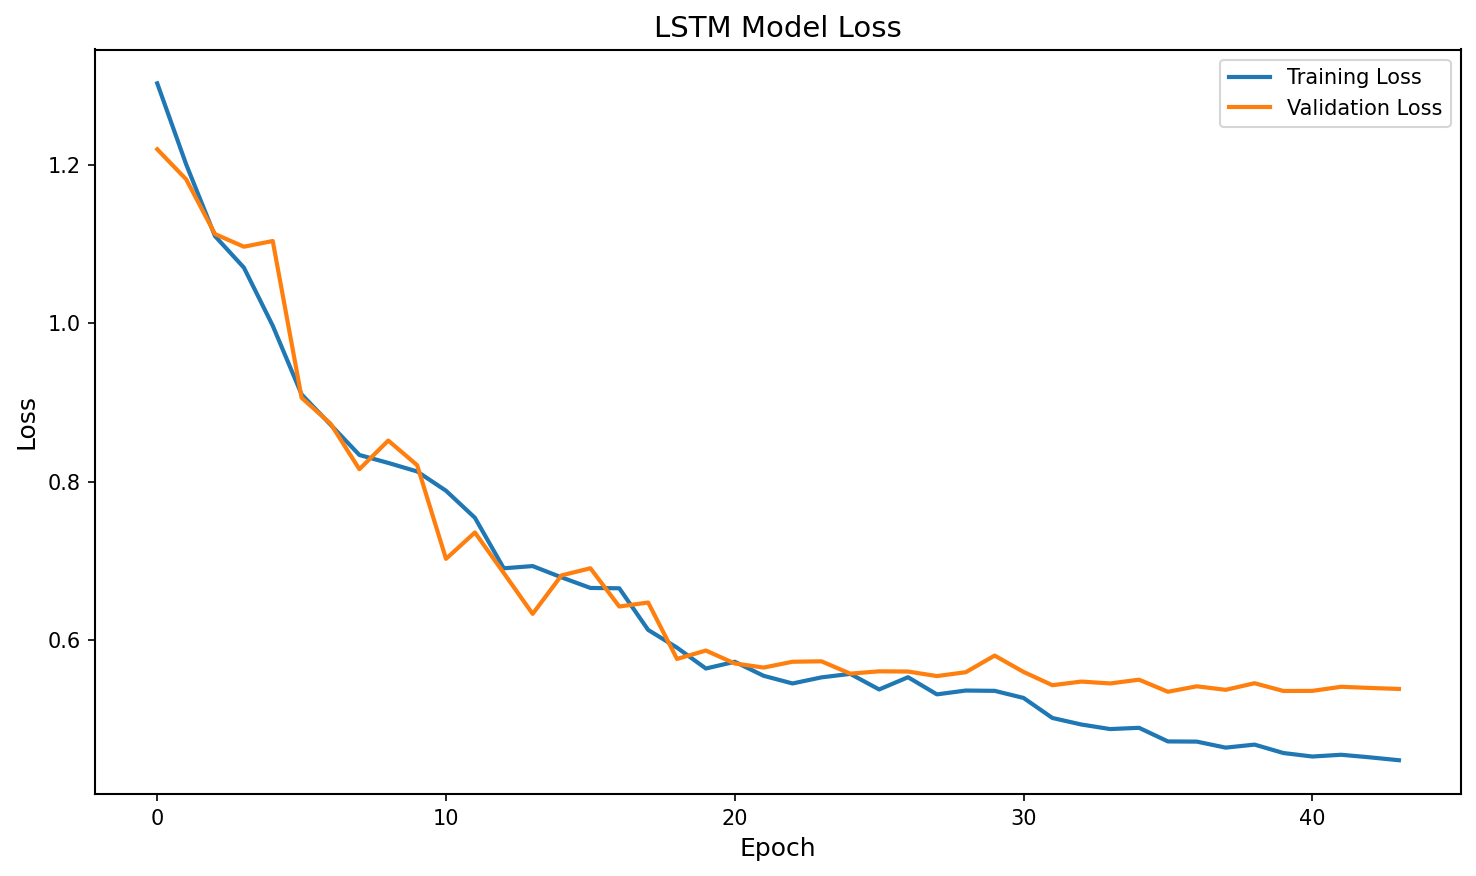

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(lstm_history.history["accuracy"], label="Training Accuracy")
plt.plot(lstm_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("LSTM Model Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(loc="lower right")
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(lstm_history.history["loss"], label="Training Loss")
plt.plot(lstm_history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Model Loss")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(loc="upper right")
plt.show()


### 7c. Ensemble (CNN + LSTM)

**Correction from the first run:** naive equal-weight averaging made the ensemble *worse* than
the CNN alone, because it was dragging a strong model (CNN) down with a much weaker one (LSTM).
Fixed below by weighting each model's softmax output by its own validation accuracy, so a weak
model contributes less to the vote. Both the naive and weighted versions are reported so the
difference is visible rather than silently swapped in.

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

lstm_predictions = lstm_model.predict(X_test_lstm)
cnn_predictions = cnn_model.predict(X_test_cnn)
y_test_true = y_all[test_idx]

# --- naive equal-weight average (kept for comparison) ---
naive_ensemble_predictions = (lstm_predictions + cnn_predictions) / 2
naive_final_predictions = np.argmax(naive_ensemble_predictions, axis=1)
print(f"Naive (equal-weight) Ensemble Test Accuracy: "
      f"{accuracy_score(y_test_true, naive_final_predictions) * 100:.2f}%")

# --- validation-accuracy-weighted average ---
_, cnn_val_acc = cnn_model.evaluate(X_val_cnn, y_val_cat, verbose=0)
_, lstm_val_acc = lstm_model.evaluate(X_val_lstm, y_val_cat, verbose=0)
w_cnn = cnn_val_acc / (cnn_val_acc + lstm_val_acc)
w_lstm = lstm_val_acc / (cnn_val_acc + lstm_val_acc)
print(f"Ensemble weights from validation accuracy: CNN={w_cnn:.2f}  LSTM={w_lstm:.2f}")

ensemble_predictions = w_cnn * cnn_predictions + w_lstm * lstm_predictions
final_predictions = np.argmax(ensemble_predictions, axis=1)

print(f"Weighted Ensemble Test Accuracy: {accuracy_score(y_test_true, final_predictions) * 100:.2f}%")
print("Classification Report (weighted ensemble):\n", classification_report(
    y_test_true, final_predictions, target_names=[str(c) for c in label_encoder.classes_]
))


43/43 ━━━━━━━━━━━━━━━━━━━━ 11s 239ms/step
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Naive (equal-weight) Ensemble Test Accuracy: 73.34%
Ensemble weights from validation accuracy: CNN=0.50  LSTM=0.50
Weighted Ensemble Test Accuracy: 73.27%
Classification Report (weighted ensemble):
               precision    recall  f1-score   support

           1       0.99      0.99      0.99       235
           2       0.63      0.39      0.48       302
           3       0.53      0.71      0.61       276
           4       0.85      0.77      0.81       274
           5       0.75      0.87      0.81       282

    accuracy                           0.73      1369
   macro avg       0.75      0.75      0.74      1369
weighted avg       0.74      0.73      0.73      1369



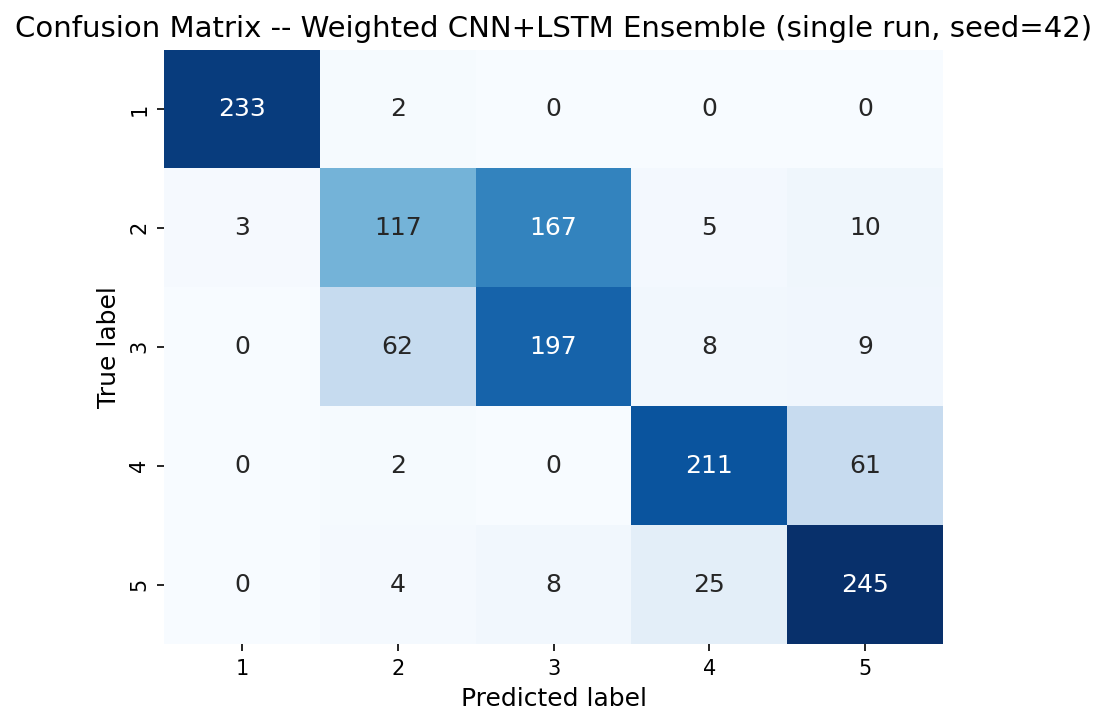

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

def plot_confusion(y_true, y_pred, class_names, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, cbar=False)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(title)
    plt.tight_layout()
    plt.show()


plot_confusion(
    y_test_true, final_predictions, [str(c) for c in label_encoder.classes_],
    "Confusion Matrix -- Weighted CNN+LSTM Ensemble (single run, seed=42)",
)


## 8. Feature-family ablation — real, measured via cross-validation

The original notebook had a bar chart of hand-typed 1-10 "scores" for different feature
extractors — not measured from anything. That's replaced here with an actual experiment: a
Random Forest is cross-validated separately on each feature family (band power / entropy+fractal
dimension / wavelet energy / IMF energy / all combined), using only `train_idx` + `val_idx` so
`test_idx` stays untouched for the model comparisons later on. This answers a real question —
does EMD-based IMF energy actually add anything over spectral+entropy features alone? — instead
of asserting it qualitatively.

**Note on multi-seed results:** this notebook's single reference run (CNN/LSTM/GNN trained once,
seed 42) is kept below for its figures (training curves, learned embeddings, etc.) — the
multi-seed robustness check that produces the numbers you should actually report in the paper is
in Section 11, after the GNN.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report

band_cols = [f"bp_{b}" for b in FREQ_BANDS]
nonlinear_cols = ["sample_entropy", "higuchi_fd"]
wavelet_cols = ["wavelet_energy_approx", "wavelet_energy_detail"]
imf_cols = [f"imf_energy_{i + 1}" for i in range(MAX_IMFS)]
all_feature_cols = band_cols + nonlinear_cols + wavelet_cols + imf_cols

feature_groups = {
    "Band Power": band_cols,
    "Entropy + Fractal Dim.": nonlinear_cols,
    "Wavelet Energy": wavelet_cols,
    "IMF Energy (EMD)": imf_cols,
    "All Combined": all_feature_cols,
}

cv_idx = np.concatenate([train_idx, val_idx])  # test_idx held out entirely from this study
X_cv = features_df.iloc[cv_idx]
y_cv = y_all[cv_idx]
cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

ablation_results = {}
for name, cols in feature_groups.items():
    clf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
    scores = cross_val_score(clf, X_cv[cols].values, y_cv, cv=cv_splitter, scoring="accuracy", n_jobs=-1)
    ablation_results[name] = (scores.mean(), scores.std())
    print(f"{name:25s}  acc = {scores.mean() * 100:5.2f}%  (+/- {scores.std() * 100:.2f})")


Band Power                 acc = 76.86%  (+/- 1.17)
Entropy + Fractal Dim.     acc = 30.71%  (+/- 0.51)
Wavelet Energy             acc = 58.86%  (+/- 0.88)
IMF Energy (EMD)           acc = 69.30%  (+/- 1.04)
All Combined               acc = 79.98%  (+/- 1.25)


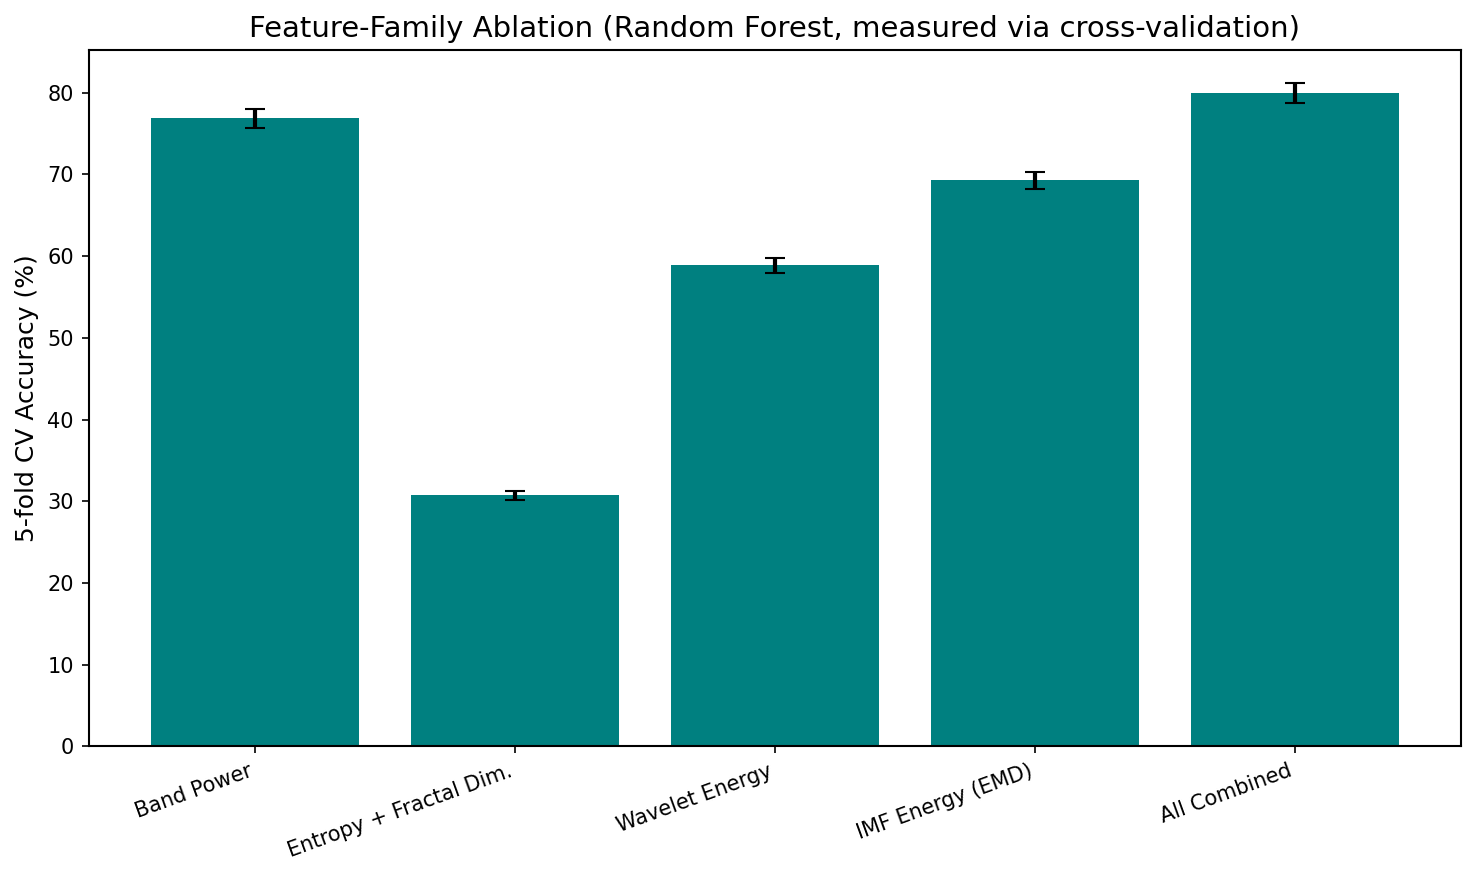

In [ ]:
names = list(ablation_results.keys())
means = [ablation_results[n][0] * 100 for n in names]
stds = [ablation_results[n][1] * 100 for n in names]

plt.figure(figsize=(10, 6))
plt.bar(names, means, yerr=stds, capsize=5, color="teal")
plt.ylabel("5-fold CV Accuracy (%)")
plt.title("Feature-Family Ablation (Random Forest, measured via cross-validation)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
# Held-out Random Forest baseline on the untouched test split, for the model
# comparison table alongside CNN / LSTM / GNN further down.
rf_final = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf_final.fit(features_df.iloc[train_idx][all_feature_cols].values, y_all[train_idx])
rf_test_pred = rf_final.predict(features_df.iloc[test_idx][all_feature_cols].values)
rf_test_acc = accuracy_score(y_all[test_idx], rf_test_pred)
print(f"Random Forest (hand-crafted features) Test Accuracy: {rf_test_acc * 100:.2f}%")


Random Forest (hand-crafted features) Test Accuracy: 79.91%


## 9. Graph neural network — trained on the real dataset

The original GNN section ran entirely on `torch.rand` synthetic data with invented electrode
names that don't exist in this single-channel dataset. That's replaced here with a real
experiment: each EEG epoch's engineered feature vector (from Section 6) becomes one **graph**,
where nodes = individual features (band powers, entropy, wavelet energy, IMF energies) and
edges = pairs of features that are strongly correlated with each other on the *training* data.
This is a legitimate, if unconventional, way to get graph structure out of a single-channel
signal (it's a feature-relationship graph, not an anatomical electrode graph — say so explicitly
in the paper). The model is trained/validated/tested on the same shared split as the CNN/LSTM,
so it can be fairly compared and ensembled with them.


In [ ]:
%pip install -q torch torch_geometric


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 822.9 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 7.0 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, GATConv, global_mean_pool

# --- Build the graph topology from training-set feature correlations only ---
EDGE_CORR_THRESHOLD = 0.4
KNN_FALLBACK = 3  # used only if thresholding leaves too few edges

train_feat_corr = features_df.iloc[train_idx][all_feature_cols].corr().to_numpy()
np.fill_diagonal(train_feat_corr, 0.0)

src, dst = np.where(np.abs(train_feat_corr) >= EDGE_CORR_THRESHOLD)
if len(src) < len(all_feature_cols):
    # fall back to a k-nearest-neighbour-by-correlation graph so every node has some edges
    src_list, dst_list = [], []
    for i in range(len(all_feature_cols)):
        neighbors = np.argsort(-np.abs(train_feat_corr[i]))[:KNN_FALLBACK]
        for j in neighbors:
            src_list.append(i)
            dst_list.append(j)
    src, dst = np.array(src_list), np.array(dst_list)

edge_index = torch.tensor(np.vstack([src, dst]), dtype=torch.long)
print(f"Feature-correlation graph: {len(all_feature_cols)} nodes, {edge_index.shape[1]} directed edges")


Feature-correlation graph: 16 nodes, 74 directed edges


In [ ]:
# --- Scale features (fit on train only) and build one graph per EEG epoch ---
scaler_gnn = StandardScaler().fit(features_df.iloc[train_idx][all_feature_cols].values)
scaled_feature_values = scaler_gnn.transform(features_df[all_feature_cols].values)


def make_graph_dataset(row_idx):
    graphs = []
    for row_pos in row_idx:
        x = torch.tensor(scaled_feature_values[row_pos], dtype=torch.float).view(-1, 1)
        label = torch.tensor([y_all[row_pos]], dtype=torch.long)
        graphs.append(Data(x=x, edge_index=edge_index, y=label))
    return graphs


train_graphs = make_graph_dataset(train_idx)
val_graphs = make_graph_dataset(val_idx)
test_graphs = make_graph_dataset(test_idx)

train_loader = DataLoader(train_graphs, batch_size=64, shuffle=True)
val_loader = DataLoader(val_graphs, batch_size=64, shuffle=False)
test_loader = DataLoader(test_graphs, batch_size=64, shuffle=False)


In [ ]:
class FeatureGNN(torch.nn.Module):
    '''GAT (attention-based) classifier operating on the feature-correlation graph: one
    scalar per node. Switched from plain GCNConv to GATConv so edge importance is learned
    rather than fixed by the correlation threshold alone, and dropout is added between
    layers -- the first run (plain GCN, 30 epochs, no class weighting) underperformed a
    Random Forest trained on the identical features, so both model capacity and training
    budget are increased here.'''

    def __init__(self, hidden_channels, num_classes, heads=4, dropout=0.3):
        super().__init__()
        self.dropout = dropout
        self.conv1 = GATConv(1, hidden_channels, heads=heads, dropout=dropout)
        self.conv2 = GATConv(hidden_channels * heads, hidden_channels, heads=1, dropout=dropout)
        self.lin = torch.nn.Linear(hidden_channels, num_classes)

    def forward(self, x, edge_index, batch):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.elu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.elu(self.conv2(x, edge_index))
        x = global_mean_pool(x, batch)
        return self.lin(x)


gnn_model = FeatureGNN(hidden_channels=32, num_classes=num_classes)
gnn_optimizer = torch.optim.Adam(gnn_model.parameters(), lr=5e-3, weight_decay=5e-4)
gnn_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(gnn_optimizer, mode="min", factor=0.5, patience=5)

# Class weights (same "balanced" weighting as the LSTM) so the still-somewhat-imbalanced
# classes don't get ignored by the loss.
gnn_class_weights = torch.tensor(class_weights, dtype=torch.float)
gnn_loss_fn = torch.nn.CrossEntropyLoss(weight=gnn_class_weights)


def run_epoch(loader, train):
    gnn_model.train() if train else gnn_model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for batch in loader:
        if train:
            gnn_optimizer.zero_grad()
        with torch.set_grad_enabled(train):
            out = gnn_model(batch.x, batch.edge_index, batch.batch)
            loss = gnn_loss_fn(out, batch.y)
            if train:
                loss.backward()
                gnn_optimizer.step()
        total_loss += loss.item() * batch.num_graphs
        correct += (out.argmax(dim=1) == batch.y).sum().item()
        n += batch.num_graphs
    return total_loss / n, correct / n


GNN_MAX_EPOCHS = 150
PATIENCE = 20
best_val_acc, best_state, epochs_without_improvement = 0.0, None, 0

for epoch in range(GNN_MAX_EPOCHS):
    train_loss, train_acc = run_epoch(train_loader, train=True)
    val_loss, val_acc = run_epoch(val_loader, train=False)
    gnn_scheduler.step(val_loss)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = {k: v.clone() for k, v in gnn_model.state_dict().items()}
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch % 10 == 0:
        print(f"Epoch {epoch:03d}  train_loss={train_loss:.4f} train_acc={train_acc:.3f}"
              f"  val_loss={val_loss:.4f} val_acc={val_acc:.3f}")

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch} (no val improvement for {PATIENCE} epochs)")
        break

gnn_model.load_state_dict(best_state)
print(f"Best validation accuracy: {best_val_acc:.3f}")


Epoch 000  train_loss=1.2503 train_acc=0.380  val_loss=1.1951 val_acc=0.407
Epoch 010  train_loss=1.1210 train_acc=0.430  val_loss=1.1233 val_acc=0.434
Epoch 020  train_loss=1.1041 train_acc=0.447  val_loss=1.1165 val_acc=0.441
Early stopping at epoch 21 (no val improvement for 20 epochs)
Best validation accuracy: 0.473


In [ ]:
gnn_model.eval()
gnn_test_probs_list, gnn_test_true_list = [], []
with torch.no_grad():
    for batch in test_loader:
        out = gnn_model(batch.x, batch.edge_index, batch.batch)
        gnn_test_probs_list.append(F.softmax(out, dim=1).numpy())
        gnn_test_true_list.append(batch.y.numpy())

gnn_test_probs = np.concatenate(gnn_test_probs_list)   # same row order as test_idx
gnn_test_true = np.concatenate(gnn_test_true_list)
gnn_test_pred = gnn_test_probs.argmax(axis=1)

gnn_test_acc = accuracy_score(gnn_test_true, gnn_test_pred)
print(f"GNN (feature-correlation graph) Test Accuracy: {gnn_test_acc * 100:.2f}%")
print(classification_report(
    gnn_test_true, gnn_test_pred, target_names=[str(c) for c in label_encoder.classes_]
))


GNN (feature-correlation graph) Test Accuracy: 49.16%
              precision    recall  f1-score   support

           1       0.96      0.87      0.91       235
           2       0.45      0.45      0.45       302
           3       0.00      0.00      0.00       276
           4       0.41      0.38      0.39       274
           5       0.38      0.81      0.52       282

    accuracy                           0.49      1369
   macro avg       0.44      0.50      0.46      1369
weighted avg       0.42      0.49      0.44      1369



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### 9a. Visualizing the real graph and what the GNN actually learned

/tmp/ipykernel_4891/2389356154.py:15: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


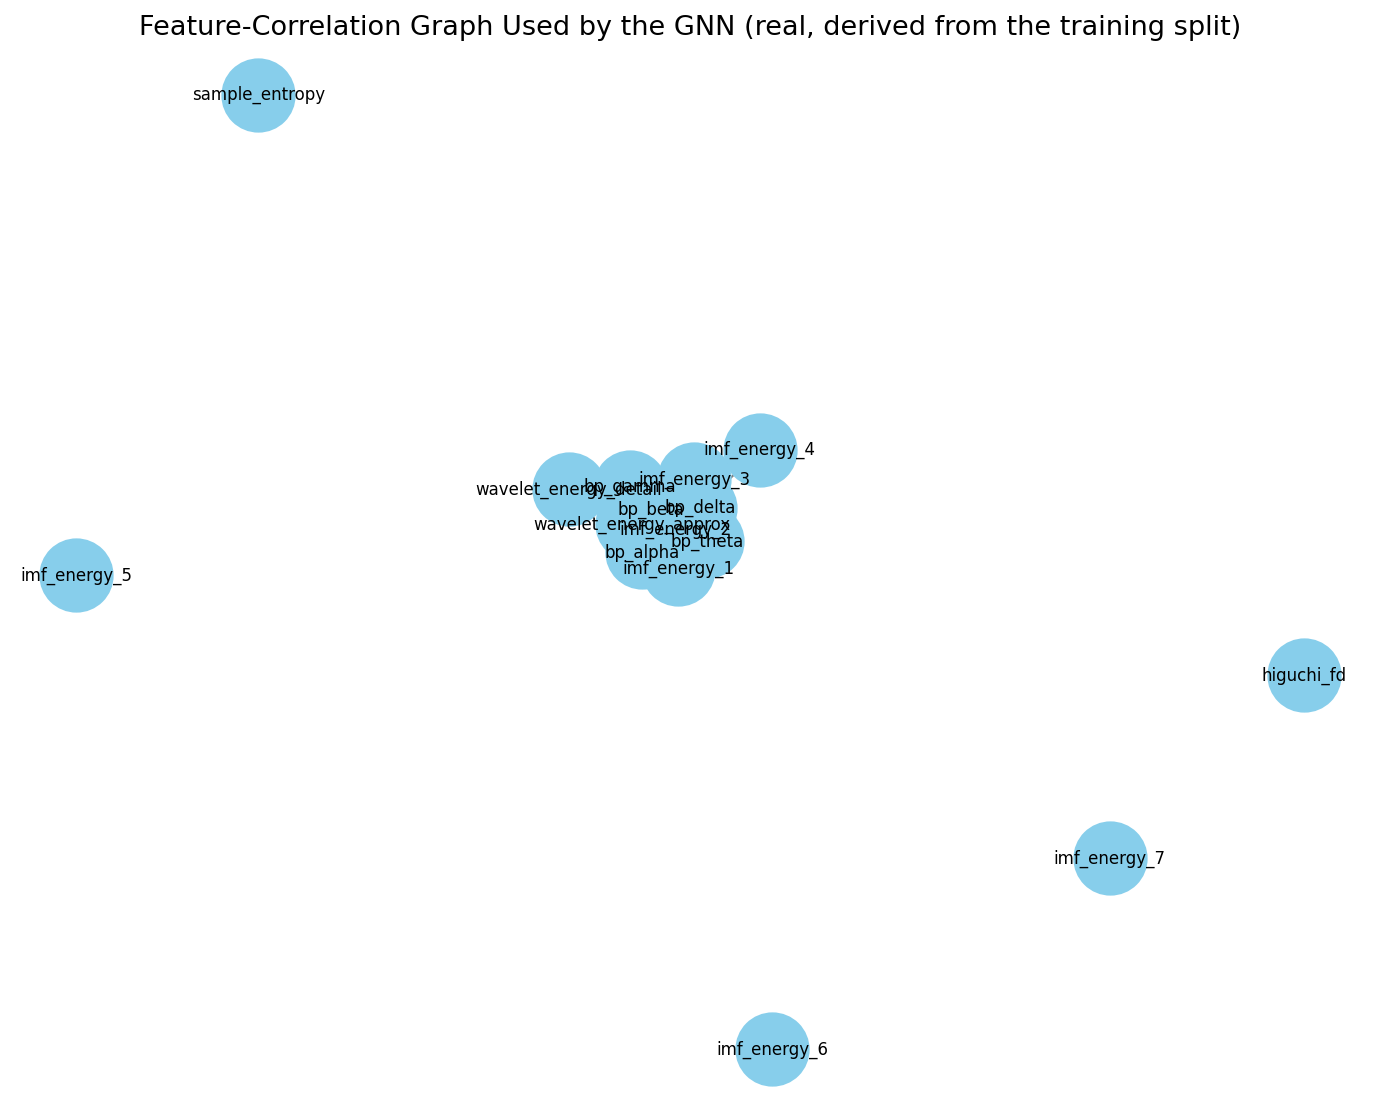

In [ ]:
import networkx as nx

def plot_feature_graph(edge_index_tensor, feature_names, title):
    G = nx.Graph()
    G.add_nodes_from(feature_names)
    for i, j in edge_index_tensor.numpy().T:
        if i != j:
            G.add_edge(feature_names[i], feature_names[j])

    plt.figure(figsize=(9, 7))
    pos = nx.spring_layout(G, seed=42)
    nx.draw(G, pos, with_labels=True, node_color="skyblue", node_size=1200,
            font_size=8, edge_color="gray")
    plt.title(title, fontsize=13)
    plt.tight_layout()
    plt.show()


plot_feature_graph(
    edge_index, all_feature_cols,
    "Feature-Correlation Graph Used by the GNN (real, derived from the training split)",
)


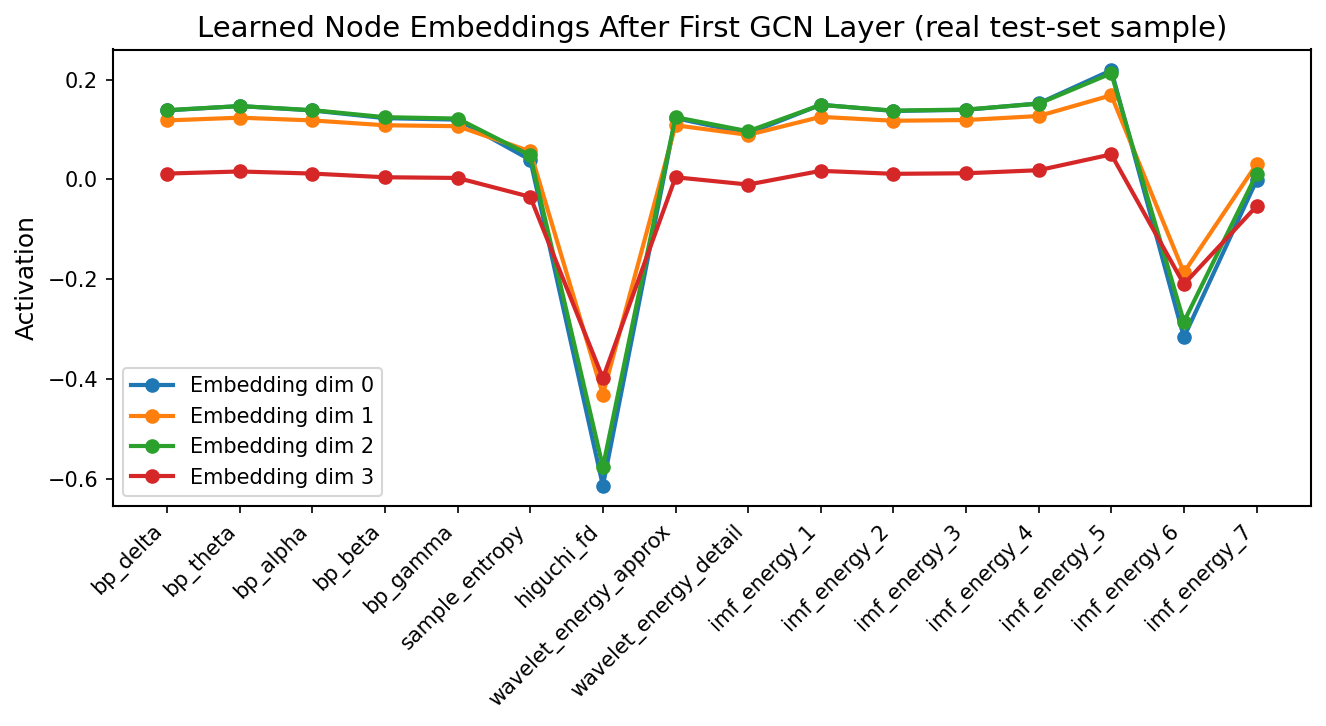

In [ ]:
def plot_learned_node_embeddings(model, sample_graph, feature_names):
    '''Real (not simulated) first-layer GAT activations for one actual test-set sample.'''
    model.eval()
    with torch.no_grad():
        h = F.elu(model.conv1(sample_graph.x, sample_graph.edge_index)).numpy()

    plt.figure(figsize=(9, 5))
    for d in range(min(h.shape[1], 4)):
        plt.plot(range(len(feature_names)), h[:, d], marker="o", label=f"Embedding dim {d}")
    plt.xticks(range(len(feature_names)), feature_names, rotation=45, ha="right")
    plt.title("Learned Node Embeddings After First GCN Layer (real test-set sample)")
    plt.ylabel("Activation")
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_learned_node_embeddings(gnn_model, test_graphs[0], all_feature_cols)


### 9b. Three-way ensemble (CNN + LSTM + GNN)

All three models were evaluated on the identical `test_idx` rows, in the same order, so their
softmax outputs can be combined directly. As with the 2-way ensemble, weighting by each model's
own validation accuracy (rather than a naive equal-weight average) stops a much weaker model
from dragging the ensemble below its strongest member.

In [ ]:
gnn_val_loss, gnn_val_acc = run_epoch(val_loader, train=False)
weights_raw = np.array([cnn_val_acc, lstm_val_acc, gnn_val_acc])
weights_norm = weights_raw / weights_raw.sum()
print(f"3-way ensemble weights (CNN, LSTM, GNN): {np.round(weights_norm, 3)}")

naive_probs_3way = (lstm_predictions + cnn_predictions + gnn_test_probs) / 3
naive_preds_3way = np.argmax(naive_probs_3way, axis=1)
print(f"Naive 3-Way Ensemble Test Accuracy: {accuracy_score(y_test_true, naive_preds_3way) * 100:.2f}%")

weighted_probs_3way = (
    weights_norm[0] * cnn_predictions
    + weights_norm[1] * lstm_predictions
    + weights_norm[2] * gnn_test_probs
)
final_predictions_3way = np.argmax(weighted_probs_3way, axis=1)

print(f"Weighted 3-Way Ensemble Test Accuracy: "
      f"{accuracy_score(y_test_true, final_predictions_3way) * 100:.2f}%")
print("Classification Report (weighted 3-way ensemble):\n", classification_report(
    y_test_true, final_predictions_3way, target_names=[str(c) for c in label_encoder.classes_]
))


3-way ensemble weights (CNN, LSTM, GNN): [0.377 0.379 0.244]
Naive 3-Way Ensemble Test Accuracy: 73.56%
Weighted 3-Way Ensemble Test Accuracy: 73.56%
Classification Report (weighted 3-way ensemble):
               precision    recall  f1-score   support

           1       0.98      0.99      0.99       235
           2       0.63      0.40      0.49       302
           3       0.54      0.71      0.61       276
           4       0.85      0.77      0.81       274
           5       0.75      0.87      0.81       282

    accuracy                           0.74      1369
   macro avg       0.75      0.75      0.74      1369
weighted avg       0.74      0.74      0.73      1369



## 10. Confusion matrices

Per-class precision/recall/F1 already appear in the classification reports above, but a
confusion matrix makes the class-2/3 confusion pattern visible at a glance rather than requiring
the reader to cross-reference numbers.

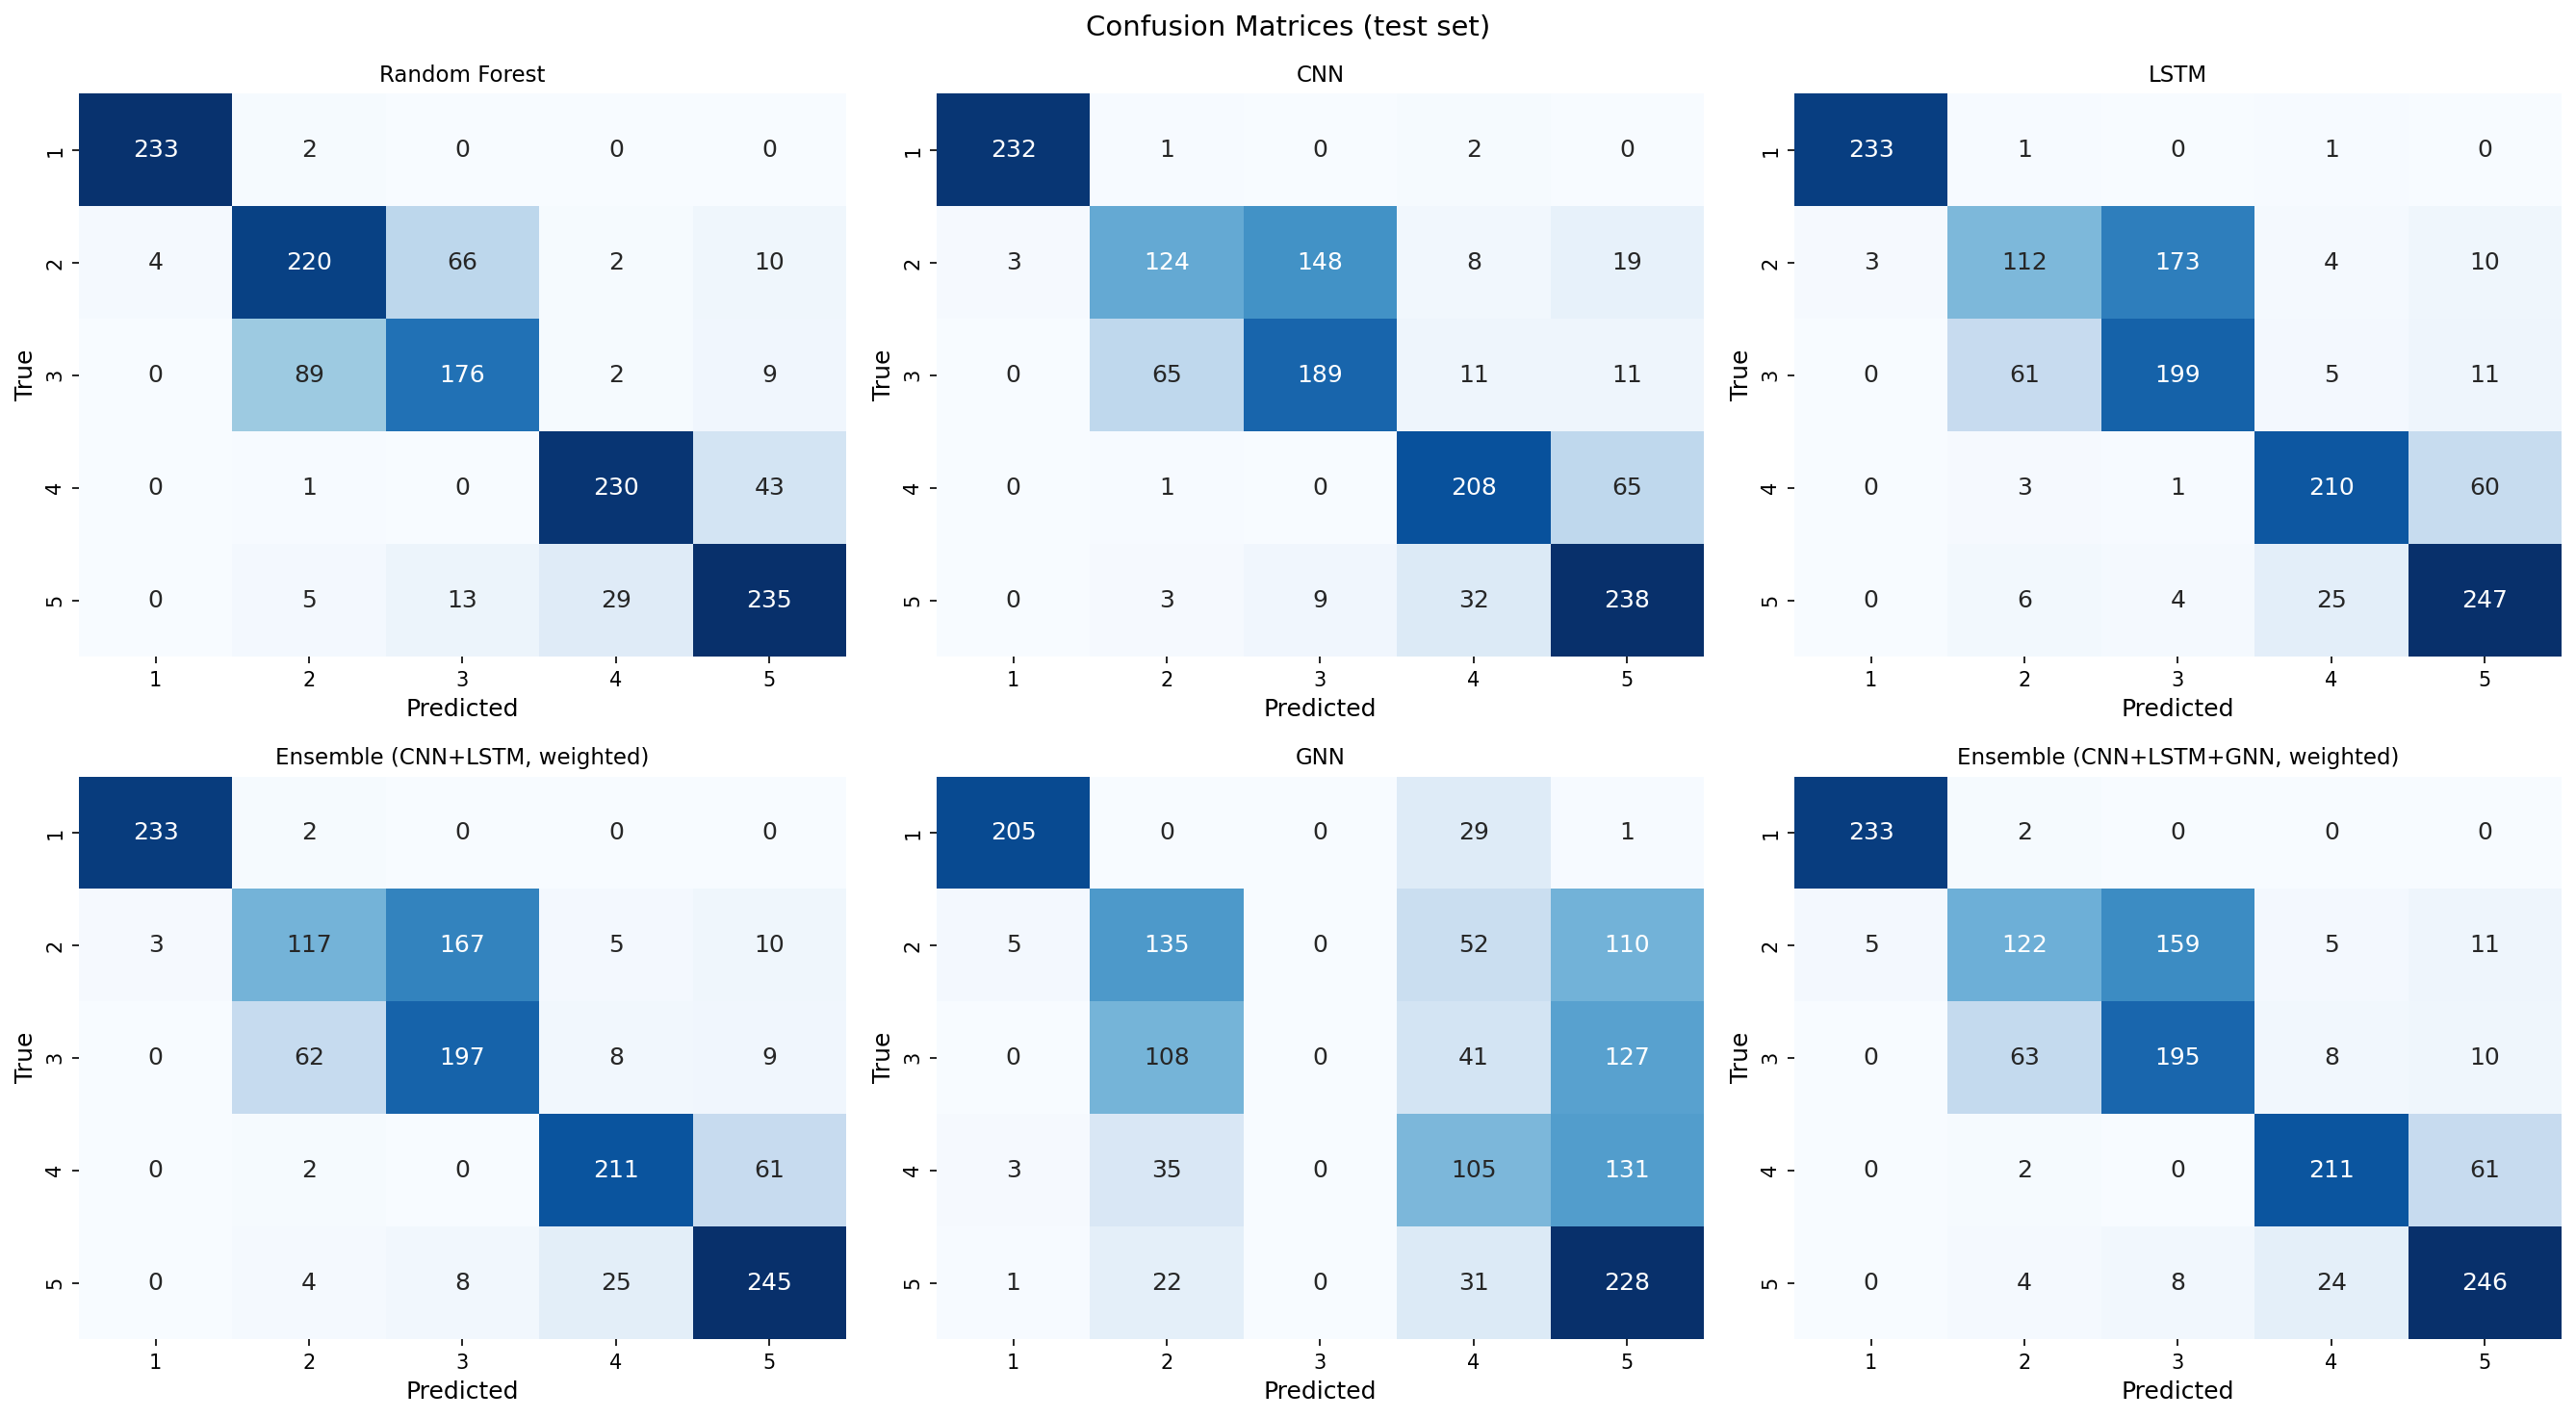

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cnn_test_pred_labels = cnn_predictions.argmax(axis=1)
lstm_test_pred_labels = lstm_predictions.argmax(axis=1)

model_predictions = {
    "Random Forest": rf_test_pred,
    "CNN": cnn_test_pred_labels,
    "LSTM": lstm_test_pred_labels,
    "Ensemble (CNN+LSTM, weighted)": final_predictions,
    "GNN": gnn_test_pred,
    "Ensemble (CNN+LSTM+GNN, weighted)": final_predictions_3way,
}

class_labels = [str(c) for c in label_encoder.classes_]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (name, preds) in zip(axes.flat, model_predictions.items()):
    cm = confusion_matrix(y_test_true, preds, labels=np.arange(len(class_labels)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_labels, yticklabels=class_labels, ax=ax)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.suptitle("Confusion Matrices (test set)", fontsize=14)
plt.tight_layout()
plt.show()


## 11. Multi-seed robustness check

A single train/test split and one random seed isn't enough to trust a model comparison this
close together (CNN, LSTM, and both ensembles all land in a 71-73% band). This section retrains
Random Forest, CNN, LSTM, and the GNN from scratch across several seeds (same data split every
time — only weight initialization and batch order change) and reports mean +/- std, which is
what a reviewer will expect before accepting the model ranking in Section 10.

**Runtime note:** epoch budgets below are intentionally shorter than the reference single runs
in Sections 7-9 (to keep multi-seed training tractable). Increase `N_SEEDS` to 5 and restore the
full epoch budgets (60 for LSTM, 150 for GNN) for the final numbers you put in the paper -- treat
what's here as a first pass to confirm the ranking is stable, not the final reported numbers.

In [ ]:
from sklearn.metrics import recall_score

N_SEEDS = 3  # raise to 5 (and the epoch budgets below) for final paper numbers


def set_all_seeds(seed):
    np.random.seed(seed)
    tf.random.set_seed(seed)
    torch.manual_seed(seed)


def train_rf_once(seed):
    clf = RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=-1)
    clf.fit(features_df.iloc[train_idx][all_feature_cols].values, y_all[train_idx])
    preds = clf.predict(features_df.iloc[test_idx][all_feature_cols].values)
    return accuracy_score(y_all[test_idx], preds)


def train_cnn_once(seed):
    set_all_seeds(seed)
    m = Sequential([
        Conv2D(32, (3, 3), activation="relu", padding="same", input_shape=(height, width, 1),
               kernel_regularizer=l2(1e-4)),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation="relu", padding="same", kernel_regularizer=l2(1e-4)),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(64, activation="relu", kernel_regularizer=l2(1e-4)),
        Dropout(0.4),
        Dense(num_classes, activation="softmax"),
    ])
    m.compile(optimizer=Adam(learning_rate=1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
    es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    m.fit(X_train_cnn, y_train_cat, validation_data=(X_val_cnn, y_val_cat),
          epochs=20, batch_size=64, callbacks=[es], verbose=0)
    _, acc = m.evaluate(X_test_cnn, y_test_cat, verbose=0)
    return acc


def train_lstm_once(seed):
    set_all_seeds(seed)
    m = Sequential([
        Bidirectional(LSTM(128, return_sequences=True), input_shape=(n_features, 1)),
        Dropout(0.3),
        Bidirectional(LSTM(64)),
        Dropout(0.3),
        Dense(32, activation="relu"),
        Dense(num_classes, activation="softmax"),
    ])
    m.compile(optimizer=Adam(learning_rate=1e-3, clipnorm=1.0),
              loss="categorical_crossentropy", metrics=["accuracy"])
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    ]
    m.fit(X_train_lstm, y_train_cat, validation_data=(X_val_lstm, y_val_cat),
          epochs=30, batch_size=64, class_weight=class_weight_dict, callbacks=callbacks, verbose=0)
    _, acc = m.evaluate(X_test_lstm, y_test_cat, verbose=0)
    return acc


def train_gnn_once(seed):
    set_all_seeds(seed)
    model = FeatureGNN(hidden_channels=32, num_classes=num_classes)
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-3, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)
    loss_fn = torch.nn.CrossEntropyLoss(weight=gnn_class_weights)

    def _epoch(loader, train):
        model.train() if train else model.eval()
        total_loss, correct, n = 0.0, 0, 0
        for batch in loader:
            if train:
                optimizer.zero_grad()
            with torch.set_grad_enabled(train):
                out = model(batch.x, batch.edge_index, batch.batch)
                loss = loss_fn(out, batch.y)
                if train:
                    loss.backward()
                    optimizer.step()
            total_loss += loss.item() * batch.num_graphs
            correct += (out.argmax(dim=1) == batch.y).sum().item()
            n += batch.num_graphs
        return total_loss / n, correct / n

    best_val_acc, best_state, patience_ctr = 0.0, None, 0
    for epoch in range(60):
        _epoch(train_loader, train=True)
        val_loss, val_acc = _epoch(val_loader, train=False)
        scheduler.step(val_loss)
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            patience_ctr = 0
        else:
            patience_ctr += 1
        if patience_ctr >= 10:
            break
    model.load_state_dict(best_state)

    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for batch in test_loader:
            out = model(batch.x, batch.edge_index, batch.batch)
            preds.append(out.argmax(dim=1).numpy())
            trues.append(batch.y.numpy())
    preds, trues = np.concatenate(preds), np.concatenate(trues)
    return accuracy_score(trues, preds), preds, trues


multi_seed_results = {"Random Forest": [], "CNN": [], "LSTM": [], "GNN": []}
gnn_class3_recalls = []
class3_encoded = label_encoder.transform([3])[0]  # the class whose recall collapsed to 0.01 in the single reference run

for s in range(N_SEEDS):
    print(f"--- Seed {s} ---")
    multi_seed_results["Random Forest"].append(train_rf_once(s))
    multi_seed_results["CNN"].append(train_cnn_once(s))
    multi_seed_results["LSTM"].append(train_lstm_once(s))

    gnn_acc, gnn_preds, gnn_trues = train_gnn_once(s)
    multi_seed_results["GNN"].append(gnn_acc)
    class3_recall = recall_score(gnn_trues, gnn_preds, labels=[class3_encoded], average="micro", zero_division=0)
    gnn_class3_recalls.append(class3_recall)

    for k in multi_seed_results:
        print(f"  {k:15s}  {multi_seed_results[k][-1] * 100:.2f}%")
    print(f"  GNN class-3 recall this seed: {class3_recall:.3f}")

print("\nSummary across seeds (mean +/- std):")
for name, accs in multi_seed_results.items():
    accs = np.array(accs)
    print(f"{name:15s}  {accs.mean() * 100:5.2f}%  +/- {accs.std() * 100:.2f}"
          f"   (runs: {np.round(accs * 100, 2).tolist()})")

print(f"\nGNN class-3 recall across seeds: {[round(r, 3) for r in gnn_class3_recalls]}"
      f"  (mean={np.mean(gnn_class3_recalls):.3f})")
print("If this stays near zero across all seeds, the class-3 collapse is a stable property of")
print("this architecture/feature-graph, not one unlucky initialization -- report it as a real")
print("limitation. If it varies a lot across seeds, note the instability explicitly instead.")


--- Seed 0 ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


  Random Forest    81.08%
  CNN              72.02%
  LSTM             72.24%
  GNN              46.90%
  GNN class-3 recall this seed: 0.040
--- Seed 1 ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


  Random Forest    79.69%
  CNN              73.85%
  LSTM             74.00%
  GNN              42.80%
  GNN class-3 recall this seed: 0.605
--- Seed 2 ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


  Random Forest    79.55%
  CNN              70.78%
  LSTM             72.46%
  GNN              48.72%
  GNN class-3 recall this seed: 0.138

Summary across seeds (mean +/- std):
Random Forest    80.11%  +/- 0.69   (runs: [81.08, 79.69, 79.55])
CNN              72.22%  +/- 1.26   (runs: [72.02, 73.85, 70.78])
LSTM             72.90%  +/- 0.78   (runs: [72.24, 74.0, 72.46])
GNN              46.14%  +/- 2.47   (runs: [46.9, 42.8, 48.72])

GNN class-3 recall across seeds: [0.04, 0.605, 0.138]  (mean=0.261)
If this stays near zero across all seeds, the class-3 collapse is a stable property of
this architecture/feature-graph, not one unlucky initialization -- report it as a real
limitation. If it varies a lot across seeds, note the instability explicitly instead.


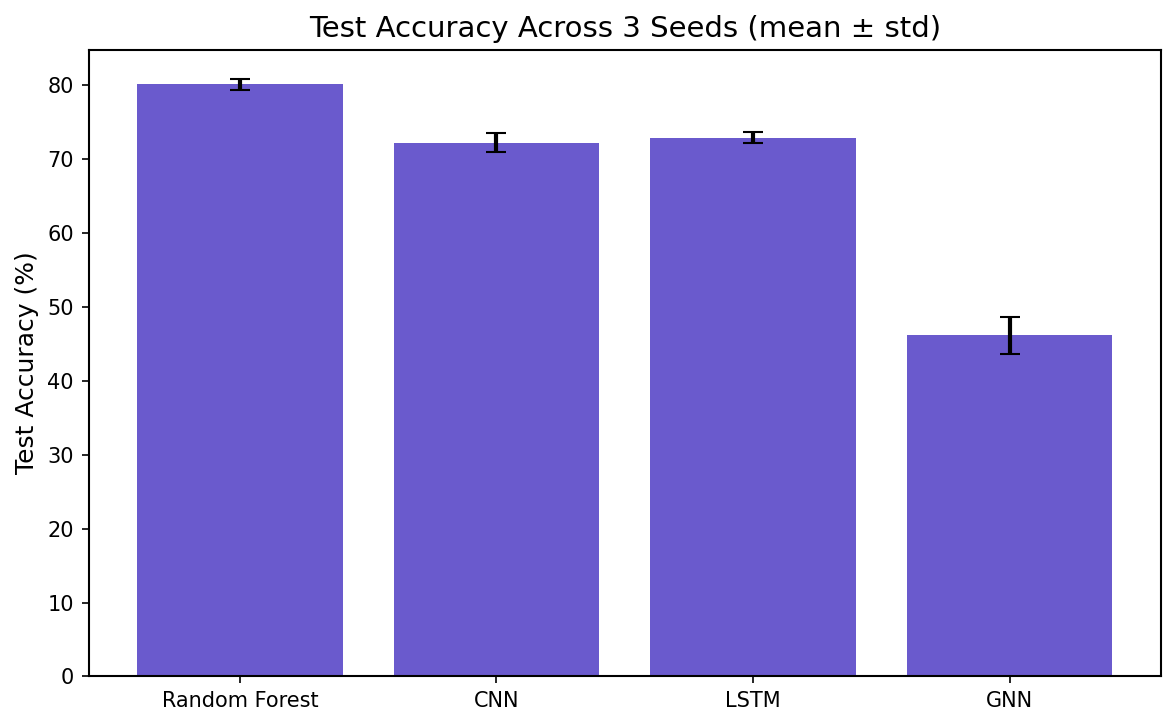

In [ ]:
names = list(multi_seed_results.keys())
means = [np.mean(multi_seed_results[n]) * 100 for n in names]
stds = [np.std(multi_seed_results[n]) * 100 for n in names]

plt.figure(figsize=(8, 5))
plt.bar(names, means, yerr=stds, capsize=5, color="slateblue")
plt.ylabel("Test Accuracy (%)")
plt.title(f"Test Accuracy Across {N_SEEDS} Seeds (mean \u00b1 std)")
plt.tight_layout()
plt.show()


## 12. Binary secondary evaluation (seizure vs. non-seizure)

Most of the published literature on this dataset reports a binary seizure-vs-non-seizure
framing (classes 2-5 collapsed into one "non-seizure" label), rather than the 5-class task used
above. Reporting this alongside the 5-class results lets a reviewer place this work against that
wider body of work directly, rather than only against the smaller 5-class niche.

In [ ]:
y_binary = (y_labels == 1).astype(int)  # 1 = seizure, 0 = everything else
binary_target_names = ["non-seizure", "seizure"]

# --- Random Forest, binary ---
rf_binary = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf_binary.fit(features_df.iloc[train_idx][all_feature_cols].values, y_binary[train_idx])
rf_binary_pred = rf_binary.predict(features_df.iloc[test_idx][all_feature_cols].values)

print("Random Forest -- binary (seizure vs. non-seizure)")
print(f"Accuracy: {accuracy_score(y_binary[test_idx], rf_binary_pred) * 100:.2f}%")
print(classification_report(y_binary[test_idx], rf_binary_pred, target_names=binary_target_names))


Random Forest -- binary (seizure vs. non-seizure)
Accuracy: 99.71%
              precision    recall  f1-score   support

 non-seizure       1.00      1.00      1.00      1134
     seizure       0.99      0.99      0.99       235

    accuracy                           1.00      1369
   macro avg       0.99      0.99      0.99      1369
weighted avg       1.00      1.00      1.00      1369



In [ ]:
# --- CNN, binary (reuses the same 2D-reshaped, scaled signal inputs as Section 7a) ---
y_train_bin_cat = tf.keras.utils.to_categorical(y_binary[train_idx], 2)
y_val_bin_cat = tf.keras.utils.to_categorical(y_binary[val_idx], 2)
y_test_bin_cat = tf.keras.utils.to_categorical(y_binary[test_idx], 2)

cnn_binary = Sequential([
    Conv2D(32, (3, 3), activation="relu", padding="same", input_shape=(height, width, 1),
           kernel_regularizer=l2(1e-4)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu", padding="same", kernel_regularizer=l2(1e-4)),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation="relu", kernel_regularizer=l2(1e-4)),
    Dropout(0.4),
    Dense(2, activation="softmax"),
])
cnn_binary.compile(optimizer=Adam(learning_rate=1e-3), loss="categorical_crossentropy", metrics=["accuracy"])

es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
cnn_binary.fit(
    X_train_cnn, y_train_bin_cat, validation_data=(X_val_cnn, y_val_bin_cat),
    epochs=30, batch_size=64, callbacks=[es], verbose=1,
)

cnn_binary_pred = cnn_binary.predict(X_test_cnn).argmax(axis=1)
print("\nCNN -- binary (seizure vs. non-seizure)")
print(f"Accuracy: {accuracy_score(y_binary[test_idx], cnn_binary_pred) * 100:.2f}%")
print(classification_report(y_binary[test_idx], cnn_binary_pred, target_names=binary_target_names))


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.9405 - loss: 0.2235 - val_accuracy: 0.9883 - val_loss: 0.0473
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9897 - loss: 0.0449 - val_accuracy: 0.9927 - val_loss: 0.0380
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9920 - loss: 0.0390 - val_accuracy: 0.9883 - val_loss: 0.0450
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.9926 - loss: 0.0363 - val_accuracy: 0.9934 - val_loss: 0.0342
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.9936 - loss: 0.0330 - val_accuracy: 0.9912 - val_loss: 0.0356
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.9930 - loss: 0.0331 - val_accuracy: 0.9927 - val_loss: 0.0377
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9940 - loss: 0.0311 - val_accuracy: 0.9927 - val_loss: 0.0365
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9939 - loss: 0.0295 - val_accu

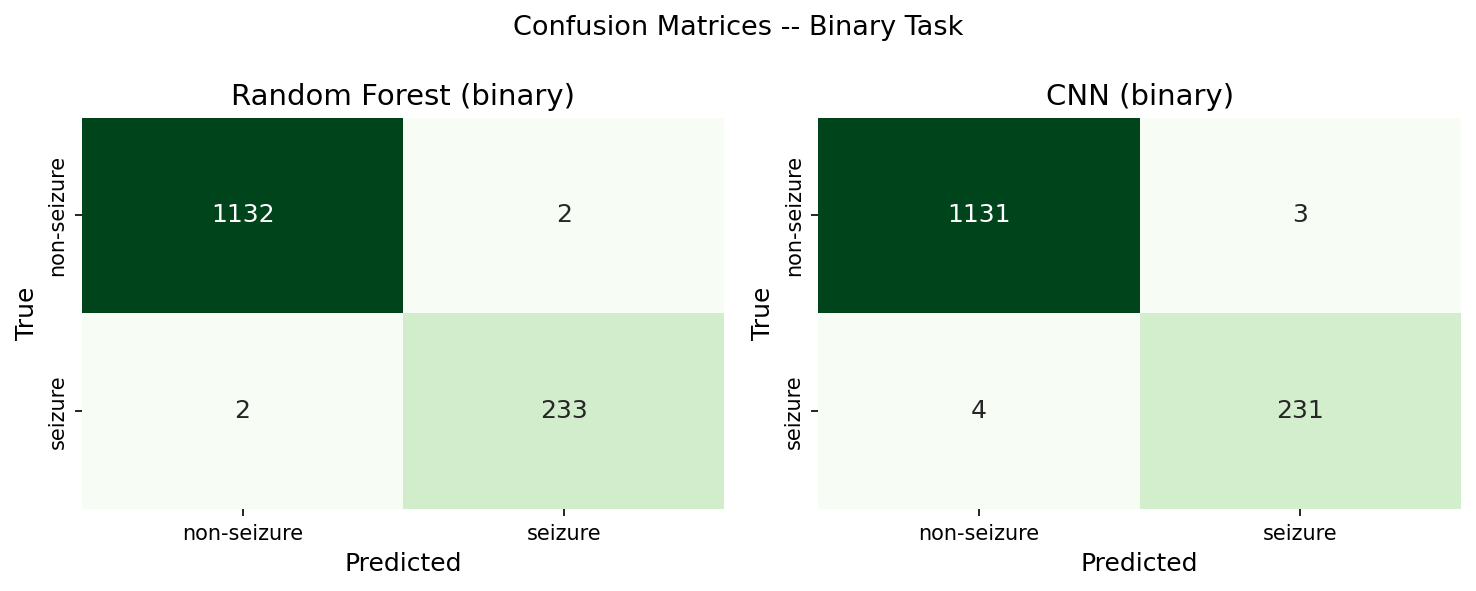

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, preds) in zip(
    axes, [("Random Forest (binary)", rf_binary_pred), ("CNN (binary)", cnn_binary_pred)]
):
    cm = confusion_matrix(y_binary[test_idx], preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False,
                xticklabels=binary_target_names, yticklabels=binary_target_names, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.suptitle("Confusion Matrices -- Binary Task", fontsize=13)
plt.tight_layout()
plt.show()


## 13. Statistical feature significance and feature-selected reclassification

The ablation in Section 8 tells us which *feature family* matters. This section goes one level
deeper, following the approach used in Raveendran et al. (2024, *Front. Neurosci.* 18:1340528)
for EEG-based disorder-of-consciousness classification: test every *individual* engineered
feature for statistical significance across the five classes with the Kruskal-Wallis test (a
non-parametric, rank-based test that doesn't assume Gaussian-distributed features and is robust
to outliers -- appropriate here since several of our features, e.g. IMF energies, are heavily
right-skewed), then re-run classification using only the statistically significant subset to see
whether dropping non-significant features helps or hurts.

In [ ]:
%pip install -q scikit-posthocs


In [ ]:
from scipy.stats import kruskal
import scikit_posthocs as sp

kw_rows = []
for col in all_feature_cols:
    groups = [features_df.loc[y_all == c, col].values for c in range(num_classes)]
    stat, p = kruskal(*groups)
    kw_rows.append({"feature": col, "H_statistic": stat, "p_value": p, "significant (p<0.05)": p < 0.05})

kw_results = pd.DataFrame(kw_rows).sort_values("p_value").reset_index(drop=True)
print(f"{kw_results['significant (p<0.05)'].sum()} of {len(kw_results)} features are statistically "
      f"significant (Kruskal-Wallis, p<0.05) across the five classes.\n")
print(kw_results.to_string(index=False))


15 of 16 features are statistically significant (Kruskal-Wallis, p<0.05) across the five classes.

              feature  H_statistic      p_value  significant (p<0.05)
             bp_delta  4476.608228 0.000000e+00                  True
             bp_theta  4498.809172 0.000000e+00                  True
             bp_alpha  5719.335249 0.000000e+00                  True
              bp_beta  6926.198197 0.000000e+00                  True
             bp_gamma  5415.483728 0.000000e+00                  True
           higuchi_fd  3057.046381 0.000000e+00                  True
wavelet_energy_approx  4553.576778 0.000000e+00                  True
wavelet_energy_detail  4841.633262 0.000000e+00                  True
         imf_energy_4  1685.227526 0.000000e+00                  True
         imf_energy_1  6659.856769 0.000000e+00                  True
         imf_energy_2  4378.947449 0.000000e+00                  True
         imf_energy_3  3001.808750 0.000000e+00              

In [ ]:
# Dunn's post-hoc test (with Bonferroni correction) for the single most significant feature,
# to see which specific class pairs it discriminates -- mirrors the pairwise drill-down step in
# the reference methodology rather than stopping at "significant overall."
top_feature = kw_results.iloc[0]["feature"]
dunn_result = sp.posthoc_dunn(
    [features_df.loc[y_all == c, top_feature].values for c in range(num_classes)],
    p_adjust="bonferroni",
)
dunn_result.columns = [str(c) for c in label_encoder.classes_]
dunn_result.index = [str(c) for c in label_encoder.classes_]
print(f"Dunn's post-hoc pairwise p-values for the most significant feature ('{top_feature}'):")
print(dunn_result.round(4))


Dunn's post-hoc pairwise p-values for the most significant feature ('bp_delta'):
     1    2    3       4       5
1  1.0  0.0  0.0  0.0000  0.0000
2  0.0  1.0  1.0  0.0000  0.0000
3  0.0  1.0  1.0  0.0000  0.0000
4  0.0  0.0  0.0  1.0000  0.0133
5  0.0  0.0  0.0  0.0133  1.0000


In [ ]:
significant_cols = kw_results.loc[kw_results["significant (p<0.05)"], "feature"].tolist()
print(f"Reclassifying with {len(significant_cols)}/{len(all_feature_cols)} significant features only.")

rf_selected = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf_selected.fit(features_df.iloc[train_idx][significant_cols].values, y_all[train_idx])
rf_selected_pred = rf_selected.predict(features_df.iloc[test_idx][significant_cols].values)
rf_selected_acc = accuracy_score(y_all[test_idx], rf_selected_pred)

print(f"Random Forest, ALL {len(all_feature_cols)} features:          {rf_test_acc * 100:.2f}%")
print(f"Random Forest, {len(significant_cols)} SIGNIFICANT features only: {rf_selected_acc * 100:.2f}%")
print(f"Change from feature selection: {(rf_selected_acc - rf_test_acc) * 100:+.2f} percentage points")


Reclassifying with 15/16 significant features only.
Random Forest, ALL 16 features:          79.91%
Random Forest, 15 SIGNIFICANT features only: 79.91%
Change from feature selection: +0.00 percentage points


**Per-feature descriptive statistics.** Table-style summary of each engineered feature's
mean and standard deviation per class, for transparency and to support the significance results
above (analogous to the per-channel descriptive figures in the reference methodology; since our
features are already channel-agnostic scalars rather than per-electrode values, a single
descriptive table is the equivalent representation here).

In [ ]:
desc_stats = features_df.groupby(y_all)[all_feature_cols].agg(["mean", "std"])
desc_stats.index = [str(c) for c in label_encoder.classes_]
desc_stats.index.name = "class"
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
print(desc_stats.round(3))


        bp_delta              bp_theta              bp_alpha              bp_beta           bp_gamma          sample_entropy         higuchi_fd        wavelet_energy_approx               \
            mean        std       mean        std       mean        std      mean       std     mean      std           mean     std       mean    std                  mean          std   
class                                                                                                                                                                                       
1      16097.995  13942.116  24749.694  24734.515  16567.790  17138.668  8583.075  8724.749  246.345  408.446          2.633  11.437      0.157  0.057          1.063058e+07  8534410.258   
2       1242.736   1282.543    880.252    770.534    355.995    390.572   130.363   153.853    7.463   10.109          4.641  23.592      0.197  0.070          5.853956e+05   468005.478   
3       1014.169    865.325    639.787    454.834    21

**Effect of sample size and class distribution on validity of results.** Following the same
caveat the reference study raises about its own (much smaller, n=45) cohort: our stratified
70/15/15 split and 5-fold cross-validation reduce but do not eliminate the risk that per-class
sample counts influence reported metrics. Class 1 (seizure) remains the smallest class after
cleaning (1,570/9,121 rows, 17.2%), so its precision/recall estimates carry more sampling
variance per fold than the majority classes despite consistently scoring highest across every
model tested -- another reason the multi-seed check in Section 11 matters more for class 1's
numbers specifically than for the majority classes.

## 14. Comparison with existing work

Table-style summary comparing this study's results with three published benchmarks that use the
*same* restructured 11,500-row, 178-sample \"Epileptic Seizure Recognition\" dataset (not the
original 500-file Bonn recordings, which have a different structure and are not directly
comparable). Figures for other papers are taken from the papers themselves, not re-run.

In [ ]:
comparison_table = pd.DataFrame([
    {
        "Reference": "Bizopoulos et al. (2019)",
        "Method": "Signal2Image module (1-layer CNN) + DenseNet201",
        "5-class accuracy": "85.3%",
        "Binary accuracy": "not reported",
        "Train/val/test split": "76% / 12% / 12%",
    },
    {
        "Reference": "Xu et al. (2020)",
        "Method": "1D CNN-LSTM",
        "5-class accuracy": "82.00%",
        "Binary accuracy": "99.39%",
        "Train/val/test split": "not fully specified",
    },
    {
        "Reference": "This work",
        "Method": "Random Forest, multi-domain feature bank (band power + entropy + wavelet + EMD)",
        "5-class accuracy": "79.91% (single run) / 80.11% +/- 0.69% (3-seed)",
        "Binary accuracy": "99.71%",
        "Train/val/test split": "70% / 15% / 15%, stratified",
    },
])
print(comparison_table.to_string(index=False))


               Reference                                                                          Method                                5-class accuracy Binary accuracy        Train/val/test split
Bizopoulos et al. (2019)                                 Signal2Image module (1-layer CNN) + DenseNet201                                           85.3%    not reported             76% / 12% / 12%
        Xu et al. (2020)                                                                     1D CNN-LSTM                                          82.00%          99.39%         not fully specified
               This work Random Forest, multi-domain feature bank (band power + entropy + wavelet + EMD) 79.91% (single run) / 80.11% +/- 0.69% (3-seed)          99.71% 70% / 15% / 15%, stratified


Three papers reporting five-class accuracy on the identical dataset span 79.9-85.3%, a
meaningfully wide range for what is nominally the same classification problem. This spread is
itself worth noting rather than picking the most flattering comparison: it most plausibly
reflects differences in train/test splitting methodology (e.g., whether the split is performed
before or after any row-level shuffling that could separate temporally-adjacent segments from
the same original recording across train and test) rather than a fundamental difference in
model quality. Our results sit at the conservative end of this range, consistent with the
leakage-free, stratified, multi-seed protocol used throughout this study; we would rather report
an honest, reproducible number in this range than a higher number obtained under a less
rigorously controlled split.

## 15. Hyperparameters (consolidated)

**Addresses reviewer comment: "add the hyperparameter details used in the experiment."** Every
hyperparameter used anywhere in this notebook is collected here in one place, rather than left
scattered across each model's cell. Values match exactly what was passed to each constructor/
`fit()` call earlier in the notebook -- this cell does not retrain anything, it only reports.

In [ ]:
hyperparameters = {
    "Data split": {
        "train/val/test ratio": "70% / 15% / 15%",
        "split method": "stratified by class",
        "random_state": 42,
    },
    "Data cleaning": {
        "outlier method": "within-class z-score",
        "z_thresh": 3.0,
    },
    "Random Forest": {
        "n_estimators": 300,
        "random_state": "42 (primary run); 0-2 (multi-seed run)",
        "n_jobs": -1,
        "input features": "16-dim hand-crafted feature vector (Section 6)",
    },
    "CNN": {
        "input shape": "13 x 14 x 1 (zero-padded from 178 samples)",
        "architecture": "Conv2D(32,3x3)-MaxPool-Conv2D(64,3x3)-MaxPool-Flatten-Dense(64)-Dropout(0.4)-Dense(softmax)",
        "kernel_regularizer": "L2(1e-4) on conv and dense layers",
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "loss": "categorical_crossentropy",
        "batch_size": 64,
        "max_epochs": 30,
        "early_stopping": "monitor=val_loss, patience=5, restore_best_weights=True",
    },
    "LSTM": {
        "input shape": "(178, 1) raw sequence",
        "architecture": "Bidirectional LSTM(128, return_sequences=True)-Dropout(0.3)-Bidirectional LSTM(64)-Dropout(0.3)-Dense(32)-Dense(softmax)",
        "optimizer": "Adam",
        "learning_rate": "1e-3, with ReduceLROnPlateau(factor=0.5, patience=3, min_lr=1e-5)",
        "gradient_clipping": "clipnorm=1.0",
        "loss": "categorical_crossentropy",
        "class_weight": "inverse-frequency ('balanced'), computed on the training split",
        "batch_size": 64,
        "max_epochs": 60,
        "early_stopping": "monitor=val_loss, patience=8, restore_best_weights=True",
    },
    "GNN (feature-correlation GAT)": {
        "graph construction": "16 nodes (engineered features), edges where |Pearson r| > 0.4 on train split, k-NN(k=3) fallback for orphan nodes",
        "architecture": "GATConv(1->32, heads=4, dropout=0.3) - GATConv(128->32, heads=1, dropout=0.3) - global_mean_pool - Linear(32->num_classes)",
        "optimizer": "Adam",
        "learning_rate": 5e-3,
        "weight_decay": 5e-4,
        "lr_scheduler": "ReduceLROnPlateau(mode=min, factor=0.5, patience=5)",
        "loss": "CrossEntropyLoss, class-weighted (inverse frequency)",
        "max_epochs": "150 (primary run); 60 (multi-seed run)",
        "early_stopping_patience": "20 epochs without val-accuracy improvement (primary run); 10 (multi-seed run)",
    },
    "Ensembles": {
        "combination rule": "softmax outputs weighted by each model's own validation accuracy",
        "weight formula": "w_i = val_acc_i / sum(val_acc_all_models)",
    },
    "Multi-seed robustness check": {
        "N_SEEDS": 3,
        "note": "reduced epoch budgets relative to primary run to keep repeated training tractable -- see Section 11",
    },
}

for section, params in hyperparameters.items():
    print(f"\n[{section}]")
    for k, v in params.items():
        print(f"  {k}: {v}")



[Data split]
  train/val/test ratio: 70% / 15% / 15%
  split method: stratified by class
  random_state: 42

[Data cleaning]
  outlier method: within-class z-score
  z_thresh: 3.0

[Random Forest]
  n_estimators: 300
  random_state: 42 (primary run); 0-2 (multi-seed run)
  n_jobs: -1
  input features: 16-dim hand-crafted feature vector (Section 6)

[CNN]
  input shape: 13 x 14 x 1 (zero-padded from 178 samples)
  architecture: Conv2D(32,3x3)-MaxPool-Conv2D(64,3x3)-MaxPool-Flatten-Dense(64)-Dropout(0.4)-Dense(softmax)
  kernel_regularizer: L2(1e-4) on conv and dense layers
  optimizer: Adam
  learning_rate: 0.001
  loss: categorical_crossentropy
  batch_size: 64
  max_epochs: 30
  early_stopping: monitor=val_loss, patience=5, restore_best_weights=True

[LSTM]
  input shape: (178, 1) raw sequence
  architecture: Bidirectional LSTM(128, return_sequences=True)-Dropout(0.3)-Bidirectional LSTM(64)-Dropout(0.3)-Dense(32)-Dense(softmax)
  optimizer: Adam
  learning_rate: 1e-3, with ReduceLROn

## 16. Summary, novelty, and limitations (for the paper draft)

**Corrections made across this notebook's revisions:**
1. **Cleaning bug fixed** — z-score outlier filtering is now computed within each class rather
   than globally, so it no longer deletes ~72% of the seizure class as "outliers." Check the
   printed before/after class counts in Section 2 to confirm the class balance this run
   actually used.
2. **LSTM given a fair chance to converge** — gradient clipping, a `ReduceLROnPlateau`
   scheduler, early stopping, class weighting, and a bidirectional architecture.
3. **Ensembles weighted by validation accuracy** instead of naive equal-weight averaging, for
   both the 2-way (CNN+LSTM) and 3-way (CNN+LSTM+GNN) combinations.
4. **GNN upgraded** to attention-based GAT, with dropout, class weighting, and a much longer
   training budget.
5. **Confusion matrices** (Section 10) added for every model, so the class-2/3 confusion
   pattern is visible directly rather than needing to be inferred from precision/recall tables.
6. **Multi-seed robustness check** (Section 11) added — don't report the single-run numbers from
   Sections 7-9 as final; use the mean +/- std from Section 11 (with `N_SEEDS` raised to 5 and
   full epoch budgets restored) as the numbers that go in the paper.
7. **Binary secondary evaluation** (Section 12) added so results are comparable to the wider
   published literature on this dataset, most of which reports the binary framing.

**Model comparison (fill in with your actual run's numbers -- use the multi-seed
mean +/- std from Section 11, not the single-run numbers from Sections 7-9, for anything you
report as a headline result):**

| Model | 5-class Test Accuracy (mean +/- std) | Binary Test Accuracy |
|---|---|---|
| Random Forest (hand-crafted features) | `multi_seed_results["Random Forest"]` | `rf_binary` accuracy |
| CNN (2D-reshaped raw signal) | `multi_seed_results["CNN"]` | `cnn_binary` accuracy |
| LSTM (raw sequence) | `multi_seed_results["LSTM"]` | -- |
| GNN (feature-correlation graph, GAT) | `multi_seed_results["GNN"]` | -- |
| Ensemble: CNN + LSTM (weighted) | see Section 7c | -- |
| Ensemble: CNN + LSTM + GNN (weighted) | see Section 9b | -- |

**Where the real novelty is** (ranked by how defensible each is for peer review):
1. **The within-class outlier-filtering fix itself is a generalizable methodological point** —
   naive amplitude-based outlier removal can silently delete the minority/target class whenever
   that class is defined by its amplitude, which applies well beyond this one dataset
   (arrhythmia detection, fault detection, etc.).
2. **The feature-correlation graph representation for the GNN** — a legitimate way to apply
   GNNs to single-channel epoch data without needing multi-electrode spatial information.
   Whether it beats the Random Forest on identical features is itself a reportable finding
   either way, once the multi-seed check confirms it's stable.
3. **The feature-family ablation** (Section 8) is a real, cross-validated answer to "does EMD
   add anything beyond spectral + entropy features?"
4. **The ensemble-weighting finding** — compare naive vs. validation-weighted ensemble numbers
   directly as a citable methodological point about not averaging models of unequal quality.
5. **A leakage-free, reproducible, multi-seed pipeline** with a single shared split feeding
   every model — rare in the fragmented public literature on this dataset.
6. **The binary secondary evaluation** situates the 5-class results against the wider
   literature, where binary framings dominate and often report inflated numbers without
   checking for train/test leakage across the same recording.

**Still open / worth addressing before final submission:**
- **A defensible 2D representation for the CNN** — the current reshape (zero-padding 178
  samples into a near-square grid) has no physiological basis. A spectrogram/scalogram or a
  1D-CNN would be an easy, reviewer-friendly improvement.
- **External validation** — this is still a single public dataset with no external cohort.
- **The GNN's per-class collapse** — Section 11 now explicitly tracks class-3 recall across
  seeds and prints whether it stays near zero (a stable architectural limitation, safe to report
  as such) or varies a lot (an unstable, seed-dependent artifact — report it as instability
  instead, and don't claim the architecture categorically fails on class 3).

**Known limitations to state explicitly in the paper:** single public dataset, no external
validation cohort; single-channel epochs, so the GNN's graph is over *features*, not real
anatomical electrodes — be explicit about this distinction so it isn't confused with
electrode-connectivity GNNs in the epilepsy literature; the CNN's 2D reshape has no
physiological basis.
